# Text Mining: Which Skills and Themes Go With Higher Pay?

**Objective.** Use the text of job postings to find which skills and wording themes are associated with higher pay, after accounting for experience, role and city, and say how certain each finding is.

**Tasks.** Text mining (skills, topics, clusters), a pay analysis (which skills and wording go with higher pay), and two classification tasks (which of 10 roles a description belongs to, and whether the posting states its pay).

**Data.** One dataset of full-text job postings collected from Naukri with an Apify scraper (`thirdwatch/naukri-jobs-scraper`). The text-mining corpus is every posting that maps to one of 10 roles. The pay analysis uses the postings that state a salary (employer-stated range, INR per year).

**Pipeline**
1. Data Preprocessing
2. Text EDA: skills, tags and what a 500-character limit would miss
3. Text Mining: skill extraction, topics, clusters
4. Feature Construction for the pay analysis
5. Experiments: does text mining help predict pay (feature sets x models)
6. Ablations: skill source, vocabulary size, topic model, text length, train/test split ratio
7. Skill and Topic Pay Premiums (three estimators, stability, placebo check)
8. Evaluation on held-out postings
9. Role Fit from the description
10. Skill bundles and text-only salary
11. Export for the dashboard
12. Business Interpretation

**Method references**
- Deming and Kahn (2018), *Skill Requirements across Firms and Labor Markets: Evidence from Job Postings for Professionals*, Journal of Labor Economics 36(S1), S337-S369. Skill measures from postings explain pay differences.
- Ao, Horvath, Sheng, Song and Sun (2022), *Skill requirements in job advertisements: a comparison of skill-categorization methods based on explanatory power in wage regressions*, arXiv:2207.12834. Compares keyword dictionaries with LDA topics, the same two routes used here.
- Chernozhukov et al. (2018), *Double/Debiased Machine Learning for Treatment and Structural Parameters*, Econometrics Journal 21(1), C1-C68 (arXiv:1608.00060). The partialling-out estimator in section 7.3.

# 1. Data Preprocessing

Load the scraped postings, assign the role from the title, clean the description, build the salary target, and form two sets: the **corpus** (all role-matched postings, for text mining) and the **pay set** (corpus postings that state a plausible salary, for the pay analysis).

In [1]:
import ast, json, re, sys, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from role_mapping import compile_rules, map_title

SEED = 42
np.random.seed(SEED)

In [2]:
raw = pd.DataFrame(json.load(open(ROOT / "data/raw/naukri_apify/merged_naukri.json")))
KEEP = ["job_id", "title", "company_name", "location", "locations", "work_mode", "experience_min", "experience_max", "skills",
        "description", "industry", "salary_min", "salary_max", "salary_currency", "salary_period", "salary_disclosed"]
df = raw[KEEP].copy()
print(f"Scraped postings: {len(df):,}   unique job_id: {df['job_id'].is_unique}")

Scraped postings: 14,085   unique job_id: True


## Step 1: Role from the title
The role comes from the title only, using the rules in `config/roles.json` through `scripts/role_mapping.py`. Titles matching two roles, an exclusion rule or no role are dropped.

In [3]:
CORE_ROLES = ["Software Engineer", "Data Analyst", "Data Scientist", "Data Engineer", "DevOps / Cloud Engineer",
              "Business Analyst", "Product Manager", "Project Manager", "Digital Marketing", "Graphic Designer"]
cfg = json.load(open(ROOT / "config/roles.json"))
rules = compile_rules([r for r in cfg["roles"] if r["role"] in CORE_ROLES])
df["role"] = df["title"].map(lambda t: map_title(t, rules)["role"])
corp = df[df["role"].notna()].copy()
print(f"Postings matched to one of the 10 roles: {len(corp):,}")

Postings matched to one of the 10 roles: 11,589


**Result.** 11,589 of 14,085 postings (82%) map to one of the ten roles.

## Step 2: Clean the description and remove repeated text
The description is plain text. Cleaning lower-cases it, removes URLs and emails, and collapses whitespace; technology names such as `c++`, `c#`, `node.js` and `ci/cd` stay intact, and nothing is lemmatised, so skill names are not distorted. Postings with an almost empty description are dropped, and **postings with an identical description are kept once**, because templated reposts would otherwise dominate topics and counts.

In [4]:
URL = re.compile(r"https?://\S+|www\.\S+|\S+@\S+\.\S+")
def clean_text(t):
    return re.sub(r"\s+", " ", URL.sub(" ", str(t)).lower()).strip()

corp["text"] = corp["description"].map(clean_text)
n0 = len(corp)
corp = corp[corp["text"].str.len() >= 50]
n1 = len(corp)
corp = corp[~corp["text"].duplicated()].reset_index(drop=True)
corp["text500"] = corp["text"].str.slice(0, 500)
print(f"{n0:,} role-matched -> {n1:,} with a real description -> {len(corp):,} after keeping identical descriptions once")
print(f"Median description length: {int(corp['text'].str.len().median())} characters")

11,589 role-matched -> 11,570 with a real description -> 10,780 after keeping identical descriptions once
Median description length: 1781 characters


**Result.** 19 descriptions are too short and are dropped, and keeping identical descriptions once removes another 790, leaving 10,780 distinct postings with a median length of 1,781 characters.

## Step 3: Posting attributes used as controls
Experience (years asked), seniority from the title, city group, work mode and industry. These are the **controls** in the pay analysis: a skill premium is only meaningful relative to postings of the same experience, role and place.

In [5]:
def seniority(title):
    t = title.lower()
    if re.search(r"\b(senior|sr|lead|principal|head|manager|director|vp|staff)\b", t): return "Senior"
    if re.search(r"\b(junior|jr|graduate|trainee|intern|entry|associate|fresher)\b", t): return "Entry"
    return "Mid"
HUBS = {"Bengaluru": "Bengaluru", "Bangalore": "Bengaluru", "Hyderabad": "Hyderabad", "Mumbai": "Mumbai", "Navi Mumbai": "Mumbai",
        "Thane": "Mumbai", "Pune": "Pune", "Chennai": "Chennai", "Kolkata": "Kolkata", "Ahmedabad": "Ahmedabad", "Kochi": "Kochi",
        "Gurugram": "Delhi NCR", "Gurgaon": "Delhi NCR", "Noida": "Delhi NCR", "Delhi": "Delhi NCR", "New Delhi": "Delhi NCR",
        "Ghaziabad": "Delhi NCR", "Faridabad": "Delhi NCR", "Greater Noida": "Delhi NCR", "Jaipur": "Jaipur"}
corp["seniority"] = corp["title"].map(seniority)
corp["city"] = corp["location"].astype(str).str.split(",").str[0].str.strip().map(HUBS).fillna("Other")
corp["exp_min"] = corp["experience_min"].fillna(corp["experience_min"].median())
corp["exp_max"] = corp["experience_max"].fillna(corp["experience_max"].median())
corp["exp_mid"] = (corp["exp_min"] + corp["exp_max"]) / 2
corp["industry"] = corp["industry"].replace("", "Unknown")
corp["company_key"] = corp["company_name"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
corp["tags"] = corp["skills"].map(lambda L: sorted({s.strip().lower() for s in L if s.strip()}) if isinstance(L, list) else [])
print(corp[["role", "seniority", "city", "exp_mid", "work_mode"]].describe(include="all").loc[["count", "unique", "top"]].T)

             count unique                top
role         10780     10  Digital Marketing
seniority    10780      3                Mid
city         10780     11          Delhi NCR
exp_mid    10780.0    NaN                NaN
work_mode    10780      3   Work from office


**Result.** All 10,780 postings get the five controls: 10 roles, 3 seniority levels, 11 city groups, an experience midpoint and 3 work modes. Digital Marketing is the biggest role and Delhi NCR the biggest city group.

## Step 4: The pay set
Postings that state a salary. As in the salary work, rows are removed when the range starts at 0 (open-ended, "up to X"), when the midpoint is below ₹100,000 a year (amounts that look monthly), or when the same title, company and range repeat. The target is `log(salary midpoint)`.

In [6]:
p = corp[corp["salary_disclosed"] & corp["salary_min"].notna() & corp["salary_max"].notna()].copy()
assert (p["salary_period"] == "yearly").all() and (p["salary_currency"] == "INR").all()
p["mid"] = (p["salary_min"] + p["salary_max"]) / 2
n_stated = len(p)
p = p[(p["salary_min"] > 0) & (p["mid"] >= 100_000)]
n_plaus = len(p)
p = p[~(p["title"].str.lower() + "|" + p["company_name"].str.lower() + "|" + p["salary_min"].astype(str) + "|" + p["salary_max"].astype(str)).duplicated()]
p["y"] = np.log(p["mid"])
pay = p.copy()
top_ind = pay["industry"].value_counts().head(12).index
corp["industry_g"] = corp["industry"].where(corp["industry"].isin(top_ind), "Other")
pay["industry_g"] = corp.loc[pay.index, "industry_g"]
print(f"Corpus: {len(corp):,} postings | with a stated salary: {n_stated:,} | plausible: {n_plaus:,} | pay set after repeats removed: {len(pay):,} postings from {pay['company_key'].nunique():,} companies")
print(pay["role"].value_counts().to_string())

Corpus: 10,780 postings | with a stated salary: 1,389 | plausible: 1,357 | pay set after repeats removed: 1,348 postings from 1,016 companies
role
Digital Marketing          370
Graphic Designer           171
Project Manager            163
DevOps / Cloud Engineer    149
Data Analyst                91
Software Engineer           87
Product Manager             86
Data Engineer               84
Business Analyst            78
Data Scientist              69


**Result.** 1,389 postings state a salary; 32 are removed as implausible and 9 as repeats, leaving 1,348 from 1,016 companies for the pay analysis.

# 2. Text EDA

What the postings contain: length, the skill tags employers attach, how the tags differ by role, and how much of that content a 500-character limit would have kept.

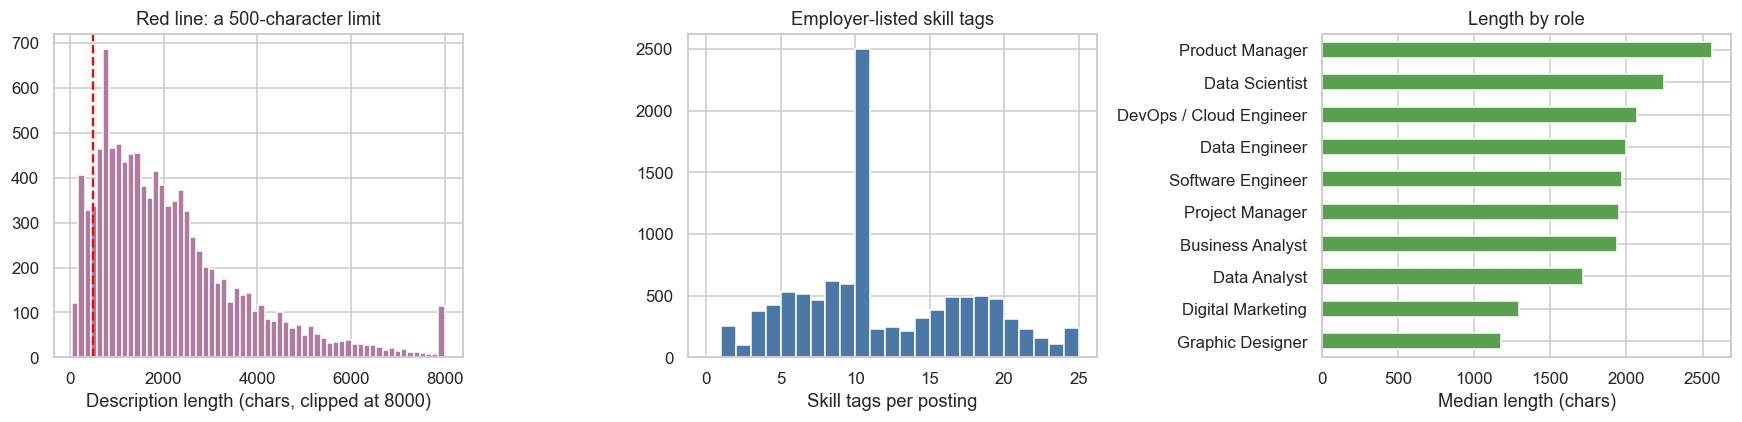

Corpus 10,780 postings | median length 1781 chars | longer than 500 chars: 90.8% | median tags per posting: 10 | no tags: 0.1%


In [7]:
L = corp["text"].str.len()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(L.clip(upper=8000), bins=60, color="#B07AA1"); ax[0].axvline(500, color="red", ls="--"); ax[0].set_xlabel("Description length (chars, clipped at 8000)"); ax[0].set_title("Red line: a 500-character limit")
tc = corp["tags"].map(len); ax[1].hist(tc.clip(upper=25), bins=25, color="#4C78A8"); ax[1].set_xlabel("Skill tags per posting"); ax[1].set_title("Employer-listed skill tags")
corp.groupby("role")["text"].apply(lambda s: s.str.len().median()).sort_values().plot.barh(ax=ax[2], color="#59A14F"); ax[2].set_xlabel("Median length (chars)"); ax[2].set_ylabel(""); ax[2].set_title("Length by role")
plt.tight_layout(); plt.show()
print(f"Corpus {len(corp):,} postings | median length {int(L.median())} chars | longer than 500 chars: {(L > 500).mean():.1%} | median tags per posting: {int(tc.median())} | no tags: {(tc == 0).mean():.1%}")

## 2.1 Skill tags
Naukri postings carry skill tags chosen by the employer. They are independent of the description wording, so they serve both as a skill vocabulary and as a check on text-based extraction. The vocabulary is the 200 most common tags that appear in at least 20 postings.

Distinct tags: 8,664; vocabulary (>= 20 postings): 200
Most common: ['python (1882)', 'agile (1623)', 'sql (1592)', 'digital marketing (1278)', 'analytics (1239)', 'seo (1179)', 'automation (1076)', 'project management (1076)', 'cloud (1033)', 'aws (998)', 'communication skills (898)', 'ai (835)', 'google analytics (749)', 'architecture (738)', 'data analysis (714)']


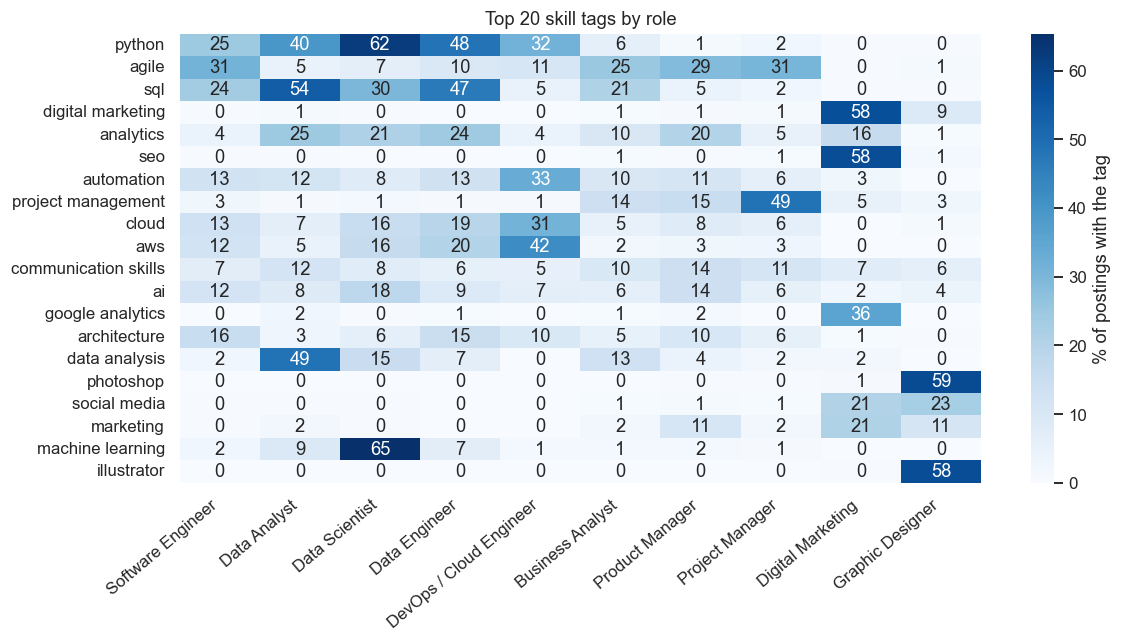

In [8]:
tag_counts = Counter(t for L_ in corp["tags"] for t in L_)
VOCAB = [t for t, c in tag_counts.most_common(200) if c >= 20]
T = pd.DataFrame({t: corp["tags"].map(lambda L_, t=t: t in L_) for t in VOCAB})
print(f"Distinct tags: {len(tag_counts):,}; vocabulary (>= 20 postings): {len(VOCAB)}")
print("Most common:", [f"{t} ({tag_counts[t]})" for t in VOCAB[:15]])
top = VOCAB[:20]
share = T[top].groupby(corp["role"].values).mean().T * 100
plt.figure(figsize=(11, 6)); sns.heatmap(share[CORE_ROLES], annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of postings with the tag"})
plt.title("Top 20 skill tags by role"); plt.ylabel(""); plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

**Result.** Employers used 8,664 distinct tags; the 200 that appear in at least 20 postings form the vocabulary. Python (1,882 postings), agile, sql, digital marketing and analytics lead.

## 2.2 Skills found in the description text
Each vocabulary tag is searched for in the description with a whole-word pattern (so `java` does not match `javascript`, and `c++` and `.net` stay intact). Tags that are very short or ordinary words (`r`, `c`, `go`, `ml`, `ai`, `bi`, `sap`) cannot be matched safely in free text, so for those only the employer tag counts. The result is a second skill matrix, **mined from the text**, next to the tag matrix.

In [9]:
AMBIG = {"r", "c", "go", "ml", "ai", "bi", "sap"}
def mine(texts, vocab):
    out = {}
    for t in vocab:
        if t in AMBIG or len(t) < 3:
            out[t] = np.zeros(len(texts), dtype=bool); continue
        rx = re.compile(r"(?<![a-z0-9+#])" + re.escape(t) + r"(?![a-z0-9+#])")
        out[t] = texts.map(lambda s: bool(rx.search(s))).values
    return pd.DataFrame(out, index=texts.index)

M = mine(corp["text"], VOCAB)
U = T | M
print(f"Postings with at least one vocabulary skill: tags {T.any(axis=1).mean():.1%} | text {M.any(axis=1).mean():.1%} | either {U.any(axis=1).mean():.1%}")
print(f"Mean skills per posting: tags {T.sum(axis=1).mean():.1f} | text {M.sum(axis=1).mean():.1f} | either {U.sum(axis=1).mean():.1f}")

Postings with at least one vocabulary skill: tags 96.3% | text 99.1% | either 99.9%
Mean skills per posting: tags 6.1 | text 12.6 | either 14.3


**Result.** The description names 12.6 vocabulary skills per posting against 6.1 tagged by the employer, and 99.9% of postings mention at least one skill, so tags alone capture less than half of what the text asks for (6.1 of 14.3 skills per posting when the two are combined).

## 2.3 What a 500-character limit would have missed
For each posting that carries a tag, was the skill named in the description at all, and was it named in the first 500 characters? Only tags that can be matched in text are counted. This measures directly what a 500-character cut keeps.

Employer tags that can be matched in text: 24,054
  also named somewhere in the description: 72.6%
  also named in the first 500 characters : 29.1%
Skill mentions per posting, first 500 characters vs full text: 4.54 vs 12.53 (2.8x)


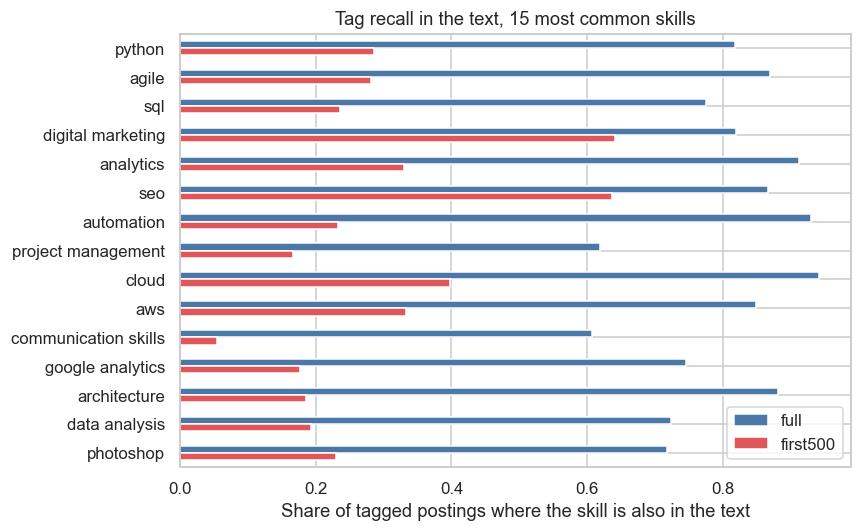

In [10]:
mineable = [t for t in VOCAB if t not in AMBIG and len(t) >= 3]
sample = corp.sample(4000, random_state=SEED)
M500 = mine(sample["text500"], mineable)
Tm, Mfull, M5 = T.loc[sample.index, mineable], M.loc[sample.index, mineable], M500
tagged = Tm.values.sum()
print(f"Employer tags that can be matched in text: {tagged:,}")
print(f"  also named somewhere in the description: {(Tm.values & Mfull.values).sum() / tagged:.1%}")
print(f"  also named in the first 500 characters : {(Tm.values & M5.values).sum() / tagged:.1%}")
print(f"Skill mentions per posting, first 500 characters vs full text: {M5.values.sum() / len(sample):.2f} vs {Mfull.values.sum() / len(sample):.2f} ({Mfull.values.sum() / max(M5.values.sum(), 1):.1f}x)")
rec = pd.DataFrame({"full": (Tm.values & Mfull.values).sum(0) / Tm.values.sum(0).clip(1), "first500": (Tm.values & M5.values).sum(0) / Tm.values.sum(0).clip(1)}, index=mineable).head(15)
rec.plot.barh(figsize=(8, 5), color=["#4C78A8", "#E15759"]); plt.gca().invert_yaxis(); plt.xlabel("Share of tagged postings where the skill is also in the text"); plt.title("Tag recall in the text, 15 most common skills"); plt.tight_layout(); plt.show()


### Reading the truncation check
- Of the 24,054 employer tags that can be matched in free text, **72.6%** are also named somewhere in the description and only **29.1%** within its first 500 characters.
- Skill mentions per posting: **4.5** in the first 500 characters against **12.5** in the full text, so a 500-character limit keeps about a third of what the text names.
- 27% of employer tags never appear in the description at all, so tags and text are two different signals, not copies of each other.
- Text matching finds more (12.6 skills per posting against 6.1 tags), partly because some vocabulary entries are ordinary words (`analytics`, `cloud`, `architecture`, `automation`). Text counts therefore mix real skills with generic words; this is a precision limit of keyword matching.


## 2.4 Skills that appear together
For the 30 most common skills: `lift` is how much more often two skills appear together than chance would give (above 1 means they travel together). Pairs seen in fewer than 30 postings are not ranked.

In [11]:
S30 = [t for t in VOCAB[:30]]
A = U[S30].values.astype(float); n = len(A)
co = A.T @ A; p = A.mean(0)
rows = [(S30[i], S30[j], int(co[i, j]), co[i, j] / (n * p[i] * p[j])) for i in range(30) for j in range(i + 1, 30) if co[i, j] >= 30]
pairs = pd.DataFrame(rows, columns=["skill_a", "skill_b", "together", "lift"]).sort_values("lift", ascending=False)
PAIRS = pairs.head(15).copy()
pairs.head(12).round(2)

,skill_a,skill_b,together,lift
257,photoshop,illustrator,821,11.24
288,illustrator,graphic designing,475,10.65
260,photoshop,graphic designing,502,10.20
313,javascript,html,392,8.69
117,seo,social media marketing,572,5.93
109,seo,google analytics,874,5.84
77,digital marketing,social media marketing,635,5.78
230,google analytics,social media marketing,357,5.29
266,social media,social media marketing,566,5.14
315,javascript,java,317,4.91


**Result.** The strongest pairs belong to one role's toolkit: Photoshop with Illustrator (lift 11.2), Illustrator with graphic designing (10.7) and JavaScript with HTML (8.7). SEO, Google Analytics and social media marketing form a marketing cluster (lift 5.3 to 5.9). These links are what the skill bundles in section 10 group.

## 2.5 Distinctive words per role
Words with the largest TF-IDF in a role relative to all postings (single words, English stop words removed).

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
TOKEN = r"(?u)\b[a-zA-Z][a-zA-Z0-9]*(?:[+#./][a-zA-Z0-9]+)*\b"
tv = TfidfVectorizer(token_pattern=TOKEN, stop_words="english", min_df=20, max_df=0.4, sublinear_tf=True)
Xtf = tv.fit_transform(corp["text"]); vocab_tf = np.array(tv.get_feature_names_out())
base = np.asarray(Xtf.mean(0)).ravel()
rows = {}
for r in CORE_ROLES:
    m = np.asarray(Xtf[(corp["role"] == r).values].mean(0)).ravel() - base
    rows[r] = ", ".join(vocab_tf[np.argsort(-m)[:8]])
TERMS = dict(rows)
pd.Series(rows, name="most distinctive words").to_frame()

,most distinctive words
Software Engineer,"software, applications, code, application, edu..."
Data Analyst,"bi, power, analyst, dashboards, reports, insig..."
Data Scientist,"machine, learning, models, ml, model, scientis..."
Data Engineer,"etl, pipelines, processing, sql, pyspark, data..."
DevOps / Cloud Engineer,"infrastructure, devops, cloud, ci/cd, kubernet..."
Business Analyst,"analyst, analysis, requirement, process, gathe..."
Product Manager,"product, products, market, roadmap, customer, ..."
Project Manager,"project, delivery, manager, risks, projects, p..."
Digital Marketing,"marketing, seo, digital, google, campaigns, me..."
Graphic Designer,"graphic, visual, creative, designer, graphics,..."


# 3. Text Mining

Two ways to turn the text into structure that can be related to pay: (a) the **skills** extracted in section 2, and (b) **topics and clusters** that group the wording without being told any skill list. Both are fitted on the corpus using text only; no salary is used.

## 3.1 Topic models
Latent Dirichlet Allocation (LDA) on word counts and Non-negative Matrix Factorisation (NMF) on TF-IDF are compared for several numbers of topics. LDA is scored by perplexity on postings held out from fitting (lower is better). Both are also scored by how well the dominant topic recovers the role (NMI, 0 to 1), as a sanity check that the topics carry real structure.

In [13]:
from sklearn.decomposition import NMF, LatentDirichletAllocation, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import normalized_mutual_info_score as nmi
import time

cv_ = CountVectorizer(token_pattern=TOKEN, stop_words="english", min_df=15, max_df=0.4)
Xc = cv_.fit_transform(corp["text"]); words = np.array(cv_.get_feature_names_out())
print(f"Topic vocabulary: {len(words):,} words, {Xc.shape[0]:,} documents")
rng = np.random.RandomState(SEED); hold = rng.rand(Xc.shape[0]) < 0.15
role_codes = corp["role"].astype("category").cat.codes.values
KS = [5, 8, 12, 16, 20]
LDA, THETA, rows = {}, {}, []
for k in KS:
    t0 = time.time()
    lda = LatentDirichletAllocation(k, learning_method="online", max_iter=12, batch_size=512, random_state=SEED, n_jobs=-1).fit(Xc[~hold])
    th = lda.transform(Xc); LDA[k], THETA[k] = lda, th
    nm = NMF(k, init="nndsvda", max_iter=300, random_state=SEED).fit(Xtf)
    thn = nm.transform(Xtf)
    rows.append({"K": k, "LDA_heldout_perplexity": lda.perplexity(Xc[hold]), "LDA_NMI_vs_role": nmi(role_codes, th.argmax(1)), "NMF_NMI_vs_role": nmi(role_codes, thn.argmax(1))})
    THETA[("nmf", k)] = thn
    print(f"K={k:2d} done in {time.time() - t0:.0f}s")
tk = pd.DataFrame(rows).set_index("K"); tk.round(3)

Topic vocabulary: 5,526 words, 10,780 documents


K= 5 done in 10s


K= 8 done in 8s


K=12 done in 10s


K=16 done in 9s


K=20 done in 10s


,LDA_heldout_perplexity,LDA_NMI_vs_role,NMF_NMI_vs_role
K,,,
5,1327.313,0.482,0.556
8,1297.623,0.484,0.501
12,1315.106,0.532,0.542
16,1308.342,0.532,0.583
20,1324.044,0.548,0.528


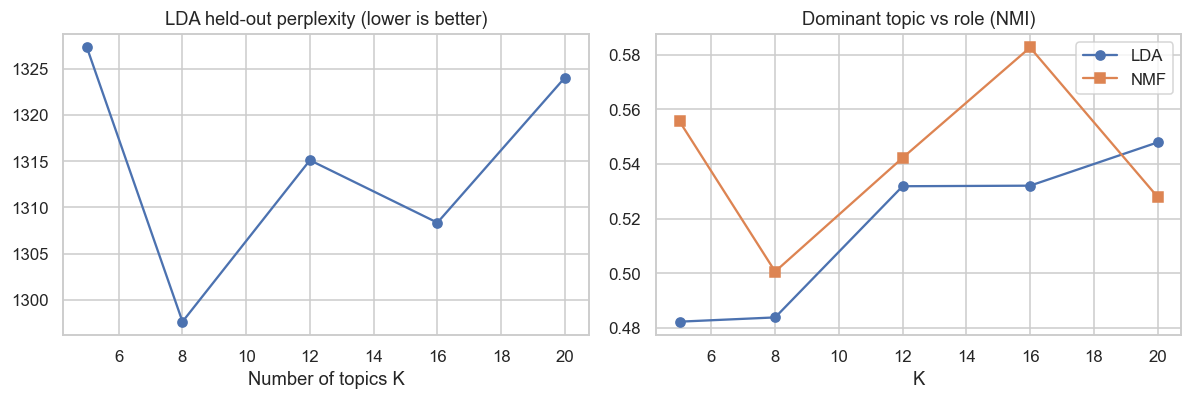

K used for the main analysis (lowest held-out perplexity): 8


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(tk.index, tk["LDA_heldout_perplexity"], "o-"); ax[0].set_xlabel("Number of topics K"); ax[0].set_title("LDA held-out perplexity (lower is better)")
ax[1].plot(tk.index, tk["LDA_NMI_vs_role"], "o-", label="LDA"); ax[1].plot(tk.index, tk["NMF_NMI_vs_role"], "s-", label="NMF"); ax[1].set_xlabel("K"); ax[1].set_title("Dominant topic vs role (NMI)"); ax[1].legend()
plt.tight_layout(); plt.show()
K_TOPIC = int(tk["LDA_heldout_perplexity"].idxmin())
print("K used for the main analysis (lowest held-out perplexity):", K_TOPIC)

In [15]:
th_main = THETA[K_TOPIC]
tw = pd.DataFrame({f"T{k}": ", ".join(words[np.argsort(-LDA[K_TOPIC].components_[k])[:9]]) for k in range(K_TOPIC)}, index=["top words"]).T
tw["share of postings (dominant)"] = [f"{(th_main.argmax(1) == k).mean():.1%}" for k in range(K_TOPIC)]
tw["main role"] = [corp.loc[th_main.argmax(1) == k, "role"].value_counts().idxmax() for k in range(K_TOPIC)]
tw

,top words,share of postings (dominant),main role
T0,"marketing, digital, seo, media, social, campai...",23.5%,Digital Marketing
T1,"project, product, delivery, stakeholders, supp...",20.6%,Project Manager
T2,"cloud, infrastructure, security, devops, azure...",8.6%,DevOps / Cloud Engineer
T3,"product, analytics, s, working, ai, insights, ...",12.0%,Data Analyst
T4,"ai, engineering, learning, models, solutions, ...",12.6%,Data Scientist
T5,"software, applications, code, technologies, sy...",8.3%,Software Engineer
T6,"details, latest, disclaimer, applying, directl...",9.1%,Digital Marketing
T7,"solutions, time, education, project, software,...",5.3%,Software Engineer


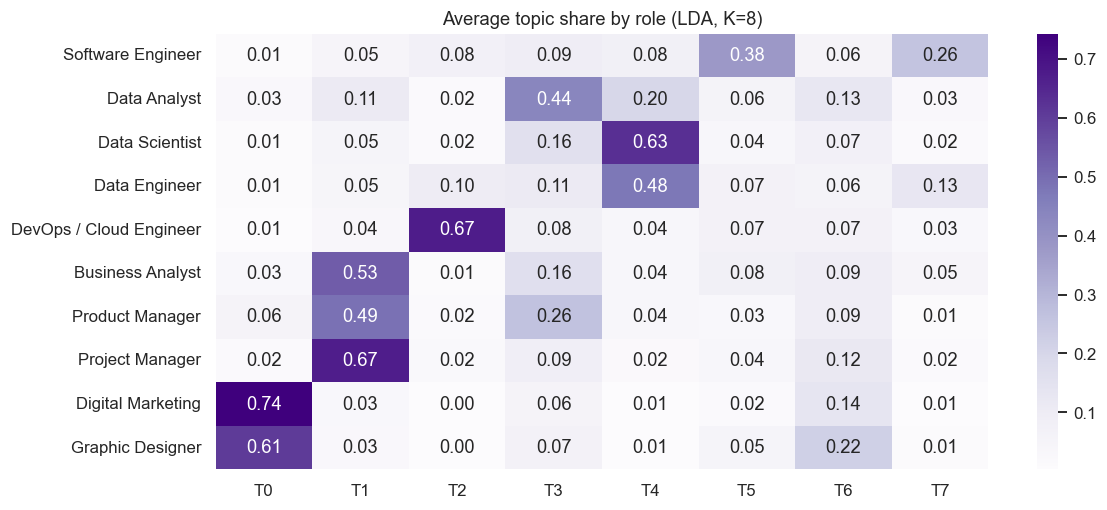

In [16]:
tr = pd.DataFrame(th_main, columns=[f"T{k}" for k in range(K_TOPIC)]).groupby(corp["role"].values).mean().loc[CORE_ROLES]
plt.figure(figsize=(11, 4.8)); sns.heatmap(tr, annot=True, fmt=".2f", cmap="Purples"); plt.title(f"Average topic share by role (LDA, K={K_TOPIC})"); plt.tight_layout(); plt.show()


### Reading the topic results
- **Number of topics.** LDA held-out perplexity is lowest at K = 8 (1,298) and is nearly flat from 5 to 20 topics (1,297 to 1,327), so K is not sharply determined. K = 8 is used.
- **Do topics recover roles?** The dominant topic matches the role with NMI 0.48 to 0.55 for LDA and 0.50 to 0.58 for NMF. NMF is higher at most K. Clusters do better (NMI 0.65), as expected: a hard grouping of a space built to separate documents.
- **What the topics are.** Topics 0, 1, 2, 3, 4 and 5 line up with Digital Marketing, project and delivery work, cloud and DevOps, analytics, AI and machine learning, and software engineering. **Topic 6** ("details, latest, disclaimer, applying, directly...") is **boilerplate**: 9.1% of postings are dominated by application and disclaimer wording, not by the job. Topic models spend capacity on boilerplate, which is a reason not to read every topic as content.


## 3.2 Clusters of postings
TF-IDF, reduced to 50 dimensions by truncated SVD and scaled to unit length, then K-Means with 12 clusters. This is the setting that worked best in the project's earlier clustering study. Clusters give a third text representation, a hard grouping, to compare with skills and topics.

NMI of clusters vs role: 0.647


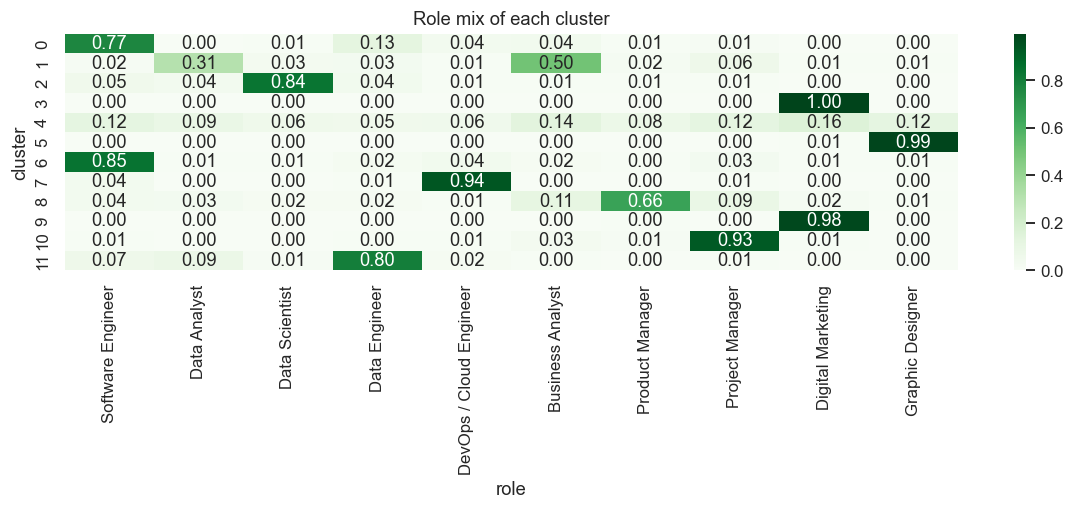

In [17]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
svd = TruncatedSVD(50, random_state=SEED); Z = svd.fit_transform(Xtf); Zn = normalize(Z)
km = KMeans(12, n_init=10, random_state=SEED).fit(Zn)
corp["cluster"] = km.labels_
print(f"NMI of clusters vs role: {nmi(role_codes, km.labels_):.3f}")
ct = pd.crosstab(corp["cluster"], corp["role"], normalize="index")[CORE_ROLES]
plt.figure(figsize=(11, 4.8)); sns.heatmap(ct, annot=True, fmt=".2f", cmap="Greens"); plt.title("Role mix of each cluster"); plt.tight_layout(); plt.show()

# 4. Feature Construction for the Pay Analysis

Everything is aligned to the pay set (postings with a stated salary). Four kinds of inputs:

| Input | What it is |
|---|---|
| **Controls** | experience (min, max, midpoint), role, seniority, city group, work mode, industry |
| **Skills** | one 0/1 column per vocabulary skill, from the employer tags, from the text, or either |
| **Topics** | LDA topic shares of the description (section 3.1) |
| **Text structure** | the 50 SVD dimensions of TF-IDF and the 12-cluster membership (section 3.2) |

The text models (vocabulary, topics, SVD, clusters) were fitted on the whole corpus using text only. No salary was used, so this does not leak the target, but the text of test companies did take part in fitting those unsupervised models.

In [18]:
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

P = pay.index.values                      # positions of the pay set inside the corpus
y, G = pay["y"].values, pay["company_key"].values
CTRL = pd.concat([pay[["exp_min", "exp_max", "exp_mid"]].astype(float),
                  pd.get_dummies(pay[["role", "seniority", "city", "work_mode", "industry_g"]]).astype(float)], axis=1)
M500p = mine(pay["text500"], VOCAB)       # skills mined from only the first 500 characters
CL = pd.get_dummies(corp["cluster"]).astype(float).loc[P].values

def skills(src, V=100, p500=False):
    voc = VOCAB[:V]
    tag, txt = T.loc[P, voc], (M500p[voc] if p500 else M.loc[P, voc])
    return {"tag": tag, "text": txt, "either": tag | txt}[src].values.astype(float)

def topics(K=None, p500=False, kind="lda"):
    K = K or K_TOPIC
    if kind == "nmf": return THETA[("nmf", K)][P]
    return LDA[K].transform(cv_.transform(pay["text500"])) if p500 else THETA[K][P]

def fs(*parts):
    return np.hstack([CTRL.values] + [p for p in parts])

SETS = {
    "F0 controls only": lambda: fs(),
    "F1 + employer tags": lambda: fs(skills("tag")),
    "F2 + skills in text": lambda: fs(skills("text")),
    "F3 + skills (tag or text)": lambda: fs(skills("either")),
    "F4 + topics": lambda: fs(topics()),
    "F5 + SVD-50": lambda: fs(Z[P]),
    "F6 + clusters": lambda: fs(CL),
    "F7 + skills, topics, SVD, clusters": lambda: fs(skills("either"), topics(), Z[P], CL),
}
X_SETS = {k: f() for k, f in SETS.items()}
print(f"Pay set: {len(pay):,} postings | controls: {CTRL.shape[1]} columns")
print({k: v.shape[1] for k, v in X_SETS.items()})

Pay set: 1,348 postings | controls: 43 columns
{'F0 controls only': 43, 'F1 + employer tags': 143, 'F2 + skills in text': 143, 'F3 + skills (tag or text)': 143, 'F4 + topics': 51, 'F5 + SVD-50': 93, 'F6 + clusters': 55, 'F7 + skills, topics, SVD, clusters': 213}


## 4.1 Train/test split
The test part is set aside first and used only in section 8. The split is **by company**, 80% train and 20% test, so no employer is on both sides. Cross-validation inside the training part is grouped by company too. Section 6.5 repeats the comparison for 70/30 and 60/40 splits.

In [19]:
gss = GroupShuffleSplit(1, test_size=0.2, random_state=SEED)
tr_i, te_i = next(gss.split(np.zeros(len(pay)), y, groups=G))
assert not set(G[tr_i]) & set(G[te_i])
print(f"Train {len(tr_i):,} postings ({len(set(G[tr_i])):,} companies) | test {len(te_i):,} postings ({len(set(G[te_i])):,} companies)")

Train 1,081 postings (812 companies) | test 267 postings (204 companies)


# 5. Experiments: Does Text Mining Help Predict Pay?

If skills and topics carry information about pay beyond experience, role and place, adding them should raise held-out accuracy. Eight feature sets are tried with four learners, scored by 5-fold company-grouped cross-validation on the training postings (R² of log salary; the spread across folds is shown).

The learners: Ridge and Lasso (linear), random forest and XGBoost (trees). The comparison within a column answers "which text representation helps"; the comparison across a row answers "which learner copes best".

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

LEARNERS = {
    "Ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=30)),
    "Lasso": lambda: make_pipeline(StandardScaler(), Lasso(alpha=0.01, max_iter=5000)),
    "Random forest": lambda: RandomForestRegressor(300, min_samples_leaf=3, max_features=0.4, n_jobs=-1, random_state=SEED),
    "XGBoost": lambda: XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.6, n_jobs=-1, random_state=SEED, verbosity=0),
}
def cv_r2(X, make, idx=tr_i, n=5):
    sc = []
    for a, b in GroupKFold(n).split(X[idx], y[idx], groups=G[idx]):
        m = make().fit(X[idx][a], y[idx][a]); sc.append(r2_score(y[idx][b], m.predict(X[idx][b])))
    return np.mean(sc), np.std(sc)
print("Ready")

Ready


,Ridge,Lasso,Random forest,XGBoost
F0 controls only,0.666,0.668,0.655,0.671
F1 + employer tags,0.633,0.664,0.667,0.671
F2 + skills in text,0.644,0.671,0.664,0.665
F3 + skills (tag or text),0.642,0.671,0.665,0.669
F4 + topics,0.673,0.675,0.669,0.675
F5 + SVD-50,0.692,0.701,0.684,0.685
F6 + clusters,0.664,0.667,0.661,0.673
"F7 + skills, topics, SVD, clusters",0.658,0.698,0.685,0.682


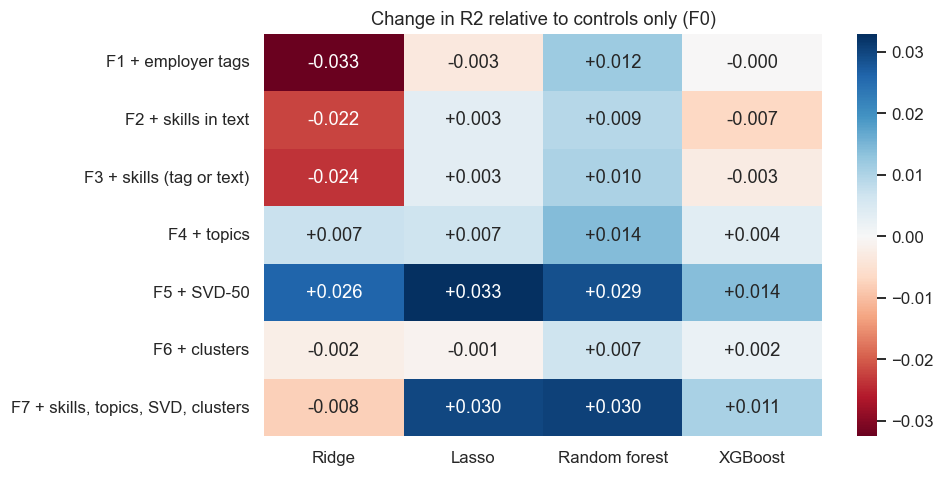

Typical fold-to-fold spread (SD of R2): 0.064


In [21]:
res = {(s, l): cv_r2(X_SETS[s], mk) for s in X_SETS for l, mk in LEARNERS.items()}
mean = pd.DataFrame({l: {s: res[(s, l)][0] for s in X_SETS} for l in LEARNERS})
sd = pd.DataFrame({l: {s: res[(s, l)][1] for s in X_SETS} for l in LEARNERS})
display(mean.round(3).style.background_gradient(cmap="Blues", axis=None).format("{:.3f}"))
gain = mean.sub(mean.loc["F0 controls only"], axis=1).drop("F0 controls only")
fig, ax = plt.subplots(figsize=(9, 4.5)); sns.heatmap(gain, annot=True, fmt="+.3f", cmap="RdBu", center=0, ax=ax); ax.set_title("Change in R2 relative to controls only (F0)")
plt.tight_layout(); plt.show()
print("Typical fold-to-fold spread (SD of R2):", round(float(sd.values.mean()), 3))


### Reading the experiment grid
- **Controls are already strong.** Experience, role, seniority, city, work mode and industry give cross-validated R² of 0.655 to 0.671 for every learner. That is the bar text features have to clear.
- **Skill columns do not help.** Employer tags, text-mined skills and both together land between 0.633 and 0.671, no better than controls alone, and Ridge is slightly worse (0.633 to 0.644): about 100 extra columns for about 1,080 training postings is more than a linear model can use.
- **Topics add a little** (+0.004 to +0.014) and **clusters almost nothing** (−0.002 to +0.006).
- **The SVD of the whole text is the only representation that helps clearly**: +0.014 to +0.033 for all four learners, best with Lasso (0.701) and Ridge (0.692). Using all text features at once is no better than SVD alone and is worse for Ridge.
- **The learner matters little.** The four learners are within 0.04 of each other on every feature set, so the signal in these features is mostly linear.
- The fold-to-fold spread (SD of R² about 0.064) is larger than any single gain, so individual cells should not be over-read. The ablation in 6.5 repeats the key comparisons 15 times per split and finds the same ranking.


# 6. Ablations

Each ablation changes one thing and keeps the rest fixed. The learner is XGBoost unless stated (Ridge is added where the contrast with a linear model is informative), the feature set is controls plus the item under test, and scores are 5-fold company-grouped cross-validation R² on the training postings.

## 6.1 Where the skills come from: employer tags, text, or both

In [22]:
rows = {}
for name, src in [("employer tags", "tag"), ("skills found in text", "text"), ("tag or text", "either")]:
    X = fs(skills(src))
    rows[name] = {"Ridge": cv_r2(X, LEARNERS["Ridge"])[0], "XGBoost": cv_r2(X, LEARNERS["XGBoost"])[0], "columns active in the pay set": int((skills(src).sum(0) > 0).sum())}
rows["(none: controls only)"] = {"Ridge": mean.loc["F0 controls only", "Ridge"], "XGBoost": mean.loc["F0 controls only", "XGBoost"], "columns active in the pay set": 0}
ABL_SOURCE = pd.DataFrame(rows).T
ABL_SOURCE.round(3)

,Ridge,XGBoost,columns active in the pay set
employer tags,0.633,0.671,97.0
skills found in text,0.644,0.665,99.0
tag or text,0.642,0.669,100.0
(none: controls only),0.666,0.671,0.0



Where the skills come from makes no difference to prediction: employer tags (R² 0.633 Ridge, 0.671 XGBoost), skills found in text (0.644, 0.665) and either (0.642, 0.669) all sit at or below the controls-only level (0.666, 0.671). Choose the source for the question being asked, not for predictive accuracy.


## 6.2 How many skills: vocabulary size

,Ridge,XGBoost
vocabulary size,,
20,0.667,0.669
40,0.660,0.674
80,0.645,0.665
150,0.634,0.671
200,0.608,0.670


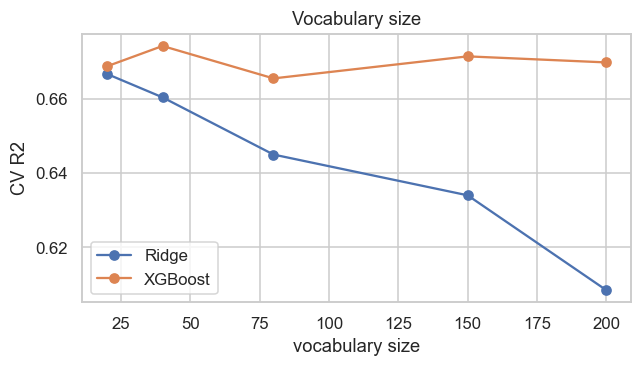

In [23]:
rows = {}
for V in (20, 40, 80, 150, 200):
    X = fs(skills("either", V))
    rows[V] = {"Ridge": cv_r2(X, LEARNERS["Ridge"])[0], "XGBoost": cv_r2(X, LEARNERS["XGBoost"])[0]}
v = pd.DataFrame(rows).T; v.index.name = "vocabulary size"
display(v.round(3))
ABL_VOCAB = v.copy()
v.plot(marker="o", figsize=(6, 3.5)); plt.ylabel("CV R2"); plt.title("Vocabulary size"); plt.tight_layout(); plt.show()


A larger vocabulary does not help, and it hurts the linear model: Ridge falls from 0.667 with 20 skills to 0.608 with 200 as the extra columns overfit, while XGBoost stays flat (0.665 to 0.674). Prediction does not need a big skill list. The premium analysis in section 7 still uses all 170 skills that have enough salaried postings, because there the aim is to measure each skill, not to predict.


## 6.3 Which topic model: LDA or NMF, and how many topics

Ridge  XGBoost
model K                 
LDA   5   0.684    0.685
      8   0.673    0.675
      12  0.679    0.679
      16  0.687    0.681
      20  0.680    0.675
NMF   5   0.674    0.668
      8   0.675    0.668
      12  0.684    0.684
      16  0.681    0.671
      20  0.678    0.681

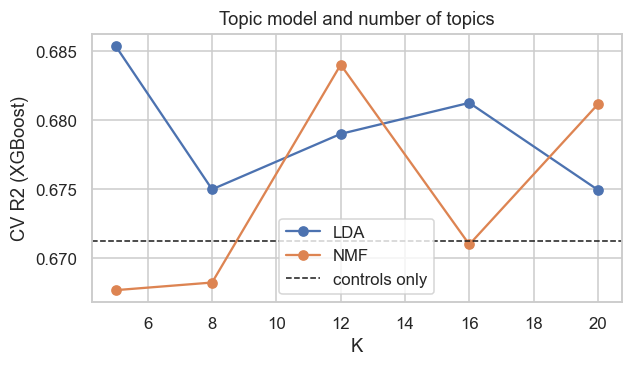

In [24]:
rows = {}
for kind in ("lda", "nmf"):
    for K in KS:
        X = fs(topics(K, kind=kind))
        rows[(kind.upper(), K)] = {"Ridge": cv_r2(X, LEARNERS["Ridge"])[0], "XGBoost": cv_r2(X, LEARNERS["XGBoost"])[0]}
t = pd.DataFrame(rows).T; t.index.names = ["model", "K"]
display(t.round(3))
ABL_TOPICS = t.copy()
t["XGBoost"].unstack(0).plot(marker="o", figsize=(6, 3.5)); plt.axhline(mean.loc["F0 controls only", "XGBoost"], color="k", ls="--", lw=1, label="controls only"); plt.legend(); plt.ylabel("CV R2 (XGBoost)"); plt.title("Topic model and number of topics"); plt.tight_layout(); plt.show()


Every topic setting lands between 0.668 and 0.687, a gain of at most about 0.02 over controls alone (0.666 Ridge, 0.671 XGBoost). LDA with 5 or 16 topics and NMF with 12 are marginally best, but the differences between models and between K values are far smaller than the fold spread. Neither the topic model nor the number of topics is a decision that matters here.


## 6.4 Full text or only the first 500 characters
Skills mined from the text and topics are recomputed from only the first 500 characters of each description. The employer tags do not depend on the description, so they are unchanged and not part of this test.

In [25]:
rows = {}
for name, X in [("skills in text, full", fs(skills("text"))), ("skills in text, first 500 chars", fs(skills("text", p500=True))),
                ("topics, full", fs(topics())), ("topics, first 500 chars", fs(topics(p500=True)))]:
    rows[name] = {"Ridge": cv_r2(X, LEARNERS["Ridge"])[0], "XGBoost": cv_r2(X, LEARNERS["XGBoost"])[0]}
rows["controls only"] = {"Ridge": mean.loc["F0 controls only", "Ridge"], "XGBoost": mean.loc["F0 controls only", "XGBoost"]}
ABL_TRUNC = pd.DataFrame(rows).T
ABL_TRUNC.round(3)

,Ridge,XGBoost
"skills in text, full",0.644,0.665
"skills in text, first 500 chars",0.645,0.676
"topics, full",0.673,0.675
"topics, first 500 chars",0.672,0.671
controls only,0.666,0.671



Cutting the text to its first 500 characters **does not reduce pay-prediction accuracy**: skills mined from the text give R² 0.645 (Ridge) and 0.676 (XGBoost) with 500 characters against 0.644 and 0.665 with the full text, and topics give 0.672 and 0.671 against 0.673 and 0.675. This is despite section 2.3 showing that the full text names 2.8 times as many skills. The reason is that skill mentions add little to pay prediction in this data (section 5), so losing most of them costs little. The 500-character limit would hurt skill demand counts, not this pay prediction.


## 6.5 Train/test split ratio
The same question under three splits: train on 80%, 70% or 60% of companies and score on the rest (20%, 30%, 40%). Each ratio is repeated with 15 random company-grouped splits; the table gives the mean and standard deviation of held-out R², and the gain over controls only is computed split by split (paired), so it is not blurred by which companies landed in the test part.

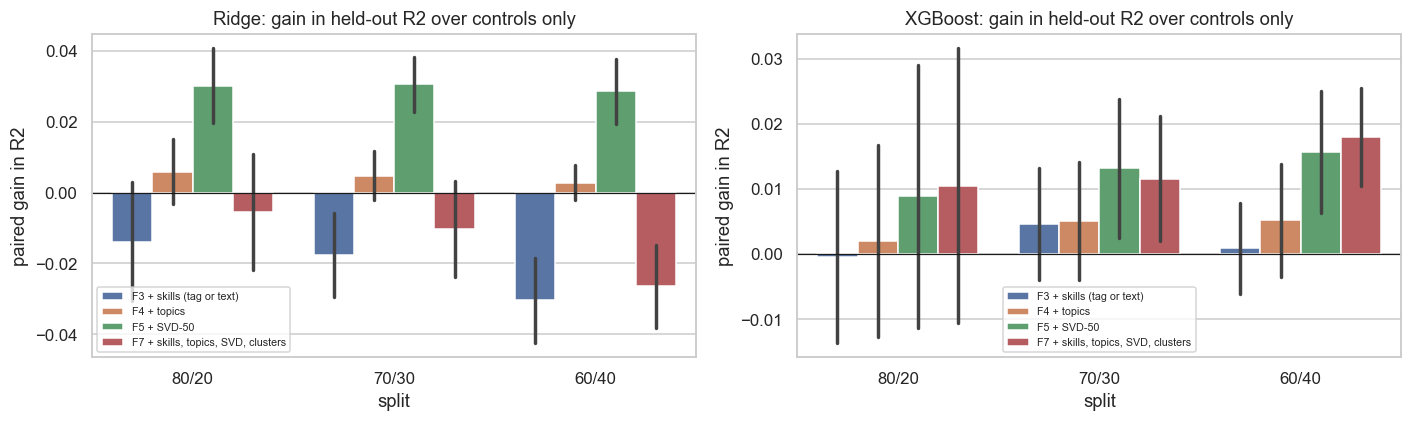

In [26]:
sets5 = ["F0 controls only", "F3 + skills (tag or text)", "F4 + topics", "F5 + SVD-50", "F7 + skills, topics, SVD, clusters"]
recs = []
for tr_frac in (0.8, 0.7, 0.6):
    for rep in range(15):
        a, b = next(GroupShuffleSplit(1, test_size=1 - tr_frac, random_state=1000 + rep).split(np.zeros(len(pay)), y, groups=G))
        for s in sets5:
            for l in ("Ridge", "XGBoost"):
                m = LEARNERS[l]().fit(X_SETS[s][a], y[a]); recs.append((f"{int(tr_frac * 100)}/{int(round((1 - tr_frac) * 100))}", rep, s, l, r2_score(y[b], m.predict(X_SETS[s][b]))))
R = pd.DataFrame(recs, columns=["split", "rep", "set", "learner", "r2"])
summ = R.groupby(["learner", "split", "set"])["r2"].agg(["mean", "std"]).round(3)
base = R[R["set"] == sets5[0]].set_index(["learner", "split", "rep"])["r2"]
R["gain"] = R["r2"] - base.reindex(pd.MultiIndex.from_frame(R[["learner", "split", "rep"]])).values
gsum = R[R["set"] != sets5[0]].groupby(["learner", "split", "set"])["gain"].agg(["mean", "std"]).round(3)
PAY_RATIO = {"mean": summ["mean"].unstack("set")[sets5], "gain": gsum["mean"].unstack("set"), "sd": summ["std"].unstack("set")[sets5]}
display(summ["mean"].unstack("set")[sets5].style.format("{:.3f}"))
display(gsum["mean"].unstack("set").style.format("{:+.3f}"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, l in zip(ax, ("Ridge", "XGBoost")):
    d = R[(R["learner"] == l) & (R["set"] != sets5[0])]
    sns.barplot(data=d, x="split", y="gain", hue="set", errorbar="sd", ax=a); a.axhline(0, color="k", lw=.8); a.set_title(f"{l}: gain in held-out R2 over controls only"); a.set_ylabel("paired gain in R2"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()


### Reading the split-ratio results
- **More training data helps a little.** Controls-only R² falls by about 0.02 as the training share drops from 80% to 60% (Ridge 0.689, 0.680, 0.671; XGBoost 0.699, 0.686, 0.673).
- **The ranking of feature sets is the same at every ratio.** The SVD of the text gives a steady paired gain: +0.030, +0.031, +0.029 for Ridge and +0.009, +0.013, +0.016 for XGBoost at 80/20, 70/30 and 60/40. Skill indicators give no gain (Ridge −0.014 to −0.030, XGBoost about 0), and topics give +0.002 to +0.006.
- **All text features together** help XGBoost (+0.011 to +0.018) but hurt Ridge (−0.005 to −0.026), the same overfitting seen in 6.2.
- So the conclusion does not depend on the particular 80/20 split: what helps is the whole wording of the description, not the listed skills.


# 7. Skill and Topic Pay Premiums

**The question.** For two postings with the same experience, role, seniority, city, work mode and industry, how much more (or less) does the one that asks for skill X pay?

**Three estimators**, so that no finding rests on one method:
1. **Marginal regression (7.1).** For each skill, regress log salary on that skill plus the controls. Standard errors are clustered by company, because postings from one employer are not independent.
2. **Joint ridge regression (7.2).** All skills enter at once, with shrinkage, so a skill is credited only for what other skills do not already explain. Intervals come from resampling companies.
3. **Double machine learning, partialling out (7.3).** Flexible boosted models predict both salary and each skill from the controls, using cross-fitting; the premium is the relation between the two leftovers (Chernozhukov et al., 2018). This removes confounding from non-linear effects of the controls.

**How to read them.** A premium of +0.10 is about +10% pay. These are associations: a skill may stand in for a better employer or a harder job. Only skills present in at least 25 salaried postings are estimated, and with about a thousand postings most intervals are wide, so the notebook reports how many estimates are distinguishable from zero and how many survive a false-discovery correction.

In [27]:
from scipy import stats

MIN_N = 25
S_all = pd.DataFrame(skills("either", 200), columns=VOCAB[:200], index=pay.index)
keep = [c for c in S_all.columns if MIN_N <= S_all[c].sum() <= len(pay) - MIN_N]
S = S_all[keep]
print(f"Skills with at least {MIN_N} salaried postings (and not universal): {len(keep)}")

def ctrl_ols(parts):
    blocks = [np.ones((len(pay), 1))]
    for c in parts:
        if c == "exp": blocks.append(np.column_stack([pay["exp_mid"], pay["exp_mid"] ** 2, pay["exp_max"] - pay["exp_min"]]).astype(float))
        else: blocks.append(pd.get_dummies(pay[c], drop_first=True).values.astype(float))
    return np.hstack(blocks)

def basis(C):
    U, s, _ = np.linalg.svd(C, full_matrices=False)
    return U[:, s > 1e-8 * s[0]]

def cluster_t(Sr, yr, beta, groups, k):
    e = yr[:, None] - Sr * beta[None, :]
    codes, uniq = pd.factorize(groups); g = len(uniq)
    cs = np.zeros((g, Sr.shape[1])); np.add.at(cs, codes, Sr * e)
    ss = (Sr ** 2).sum(0); n = len(yr)
    se = np.sqrt(g / (g - 1) * (n - 1) / (n - k) * (cs ** 2).sum(0)) / ss
    t = beta / se
    return se, t, 2 * stats.t.sf(np.abs(t), df=g - 1)

def fwl_ols(Smat, yv, C, groups):
    Q = basis(C)
    yr = yv - Q @ (Q.T @ yv); Sr = Smat - Q @ (Q.T @ Smat)
    beta = (Sr * yr[:, None]).sum(0) / (Sr ** 2).sum(0)
    se, t, p = cluster_t(Sr, yr, beta, groups, Q.shape[1] + 1)
    return beta, se, t, p

def bh(p, q=0.10):
    p = np.asarray(p); n = len(p); o = np.argsort(p); thr = q * (np.arange(1, n + 1) / n)
    ok = p[o] <= thr; k = np.max(np.where(ok)[0]) + 1 if ok.any() else 0
    sig = np.zeros(n, bool); sig[o[:k]] = True
    return sig
print("Estimators ready")

Skills with at least 25 salaried postings (and not universal): 170
Estimators ready


## 7.1 Marginal regression with full controls

In [28]:
C_full = ctrl_ols(["exp", "role", "seniority", "city", "work_mode", "industry_g"])
b1, se1, t1, p1 = fwl_ols(S.values.astype(float), y, C_full, G)
prem = pd.DataFrame({"skill": S.columns, "n_postings": S.sum().values.astype(int), "ols_beta": b1, "ols_se": se1, "ols_p": p1})
prem["ols_fdr_sig"] = bh(prem["ols_p"].values)
print(f"Skills estimated: {len(prem)} | nominal p < 0.05: {(prem['ols_p'] < .05).sum()} | significant after false-discovery control (10%): {prem['ols_fdr_sig'].sum()}")
prem.sort_values("ols_beta", ascending=False).head(10).round(3)

Skills estimated: 170 | nominal p < 0.05: 32 | significant after false-discovery control (10%): 15


,skill,n_postings,ols_beta,ols_se,ols_p,ols_fdr_sig
146,bash,54,0.263,0.077,0.001,True
31,product management,70,0.259,0.074,0.000,True
114,networking,71,0.240,0.072,0.001,True
84,performance marketing,184,0.227,0.043,0.000,True
132,product strategy,39,0.223,0.110,0.043,False
70,pmp,51,0.186,0.075,0.013,False
95,risk management,34,0.181,0.096,0.060,False
78,tableau,67,0.179,0.077,0.020,False
140,cloud infrastructure,66,0.171,0.067,0.011,False
77,analytical skills,74,0.168,0.056,0.003,True


**What this shows.** Of 170 skills, 32 have a nominal p-value below 0.05, but about 8 would be expected by chance with this many tests, which is why the false-discovery correction matters: 15 survive it at 10%. The largest positive associations are bash (+0.263 log points, about +30%), product management (+0.259, +30%), networking (+0.240, +27%) and performance marketing (+0.227, +26%). These are associations at the same role, experience, seniority, city, work mode and industry, not what a skill would add to one person's pay.

## 7.2 Joint ridge regression
All skills together, standardised, with the ridge penalty chosen by company-grouped cross-validation. The premium for a skill is its coefficient divided by the skill's standard deviation (so it is in log-salary points for the skill being present). Intervals come from 200 resamples of companies.

In [29]:
from sklearn.linear_model import RidgeCV
Xj = np.hstack([CTRL.values, S.values.astype(float)]); nC = CTRL.shape[1]
mu, sdv = Xj.mean(0), Xj.std(0) + 1e-9; Xs = (Xj - mu) / sdv
alphas = [1, 3, 10, 30, 100, 300, 1000]
cvs = [np.mean([r2_score(y[b], Ridge(alpha=a).fit(Xs[a_], y[a_]).predict(Xs[b])) for a_, b in GroupKFold(5).split(Xs, y, groups=G)]) for a in alphas]
A_BEST = alphas[int(np.argmax(cvs))]
print("Ridge penalty by CV R2:", dict(zip(alphas, np.round(cvs, 3))), "-> alpha", A_BEST)
coef = Ridge(alpha=A_BEST).fit(Xs, y).coef_[nC:] / sdv[nC:]
rng = np.random.RandomState(SEED); comp = pd.unique(G); idx_by = {c: np.where(G == c)[0] for c in comp}
boots = []
for _ in range(200):
    pick = rng.choice(comp, len(comp), replace=True); ii = np.concatenate([idx_by[c] for c in pick])
    mu_b, sd_b = Xj[ii].mean(0), Xj[ii].std(0) + 1e-9
    boots.append(Ridge(alpha=A_BEST).fit((Xj[ii] - mu_b) / sd_b, y[ii]).coef_[nC:] / sd_b[nC:])
boots = np.array(boots)
prem["ridge_beta"] = coef; prem["ridge_lo"], prem["ridge_hi"] = np.percentile(boots, [2.5, 97.5], axis=0)
prem["ridge_ci_excludes_0"] = (prem["ridge_lo"] > 0) | (prem["ridge_hi"] < 0)
print(f"Skills whose bootstrap interval excludes zero: {prem['ridge_ci_excludes_0'].sum()} of {len(prem)}")

Ridge penalty by CV R2: {1: np.float64(0.628), 3: np.float64(0.629), 10: np.float64(0.632), 30: np.float64(0.639), 100: np.float64(0.654), 300: np.float64(0.67), 1000: np.float64(0.664)} -> alpha 300


Skills whose bootstrap interval excludes zero: 25 of 170


**Result.** The ridge penalty chosen by company-grouped cross-validation is 300 (R² 0.670). 25 of 170 skills have a bootstrap interval that excludes zero, more than the 15 that survive false-discovery control in 7.1, because these intervals are not corrected for the number of skills tested.

## 7.3 Double machine learning (partialling out)
For each skill: a boosted model predicts log salary from the controls and another predicts whether the posting asks for the skill, both with 5-fold company-grouped cross-fitting (a prediction for a posting never comes from a model trained on its own company). The premium is the regression of the salary leftover on the skill leftover, with company-clustered standard errors.

In [30]:
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
Xc_ = CTRL.values
folds = list(GroupKFold(5).split(Xc_, y, groups=G))
yhat = np.zeros(len(y))
for a, b in folds:
    yhat[b] = HistGradientBoostingRegressor(max_iter=150, max_depth=3, learning_rate=0.05, random_state=SEED).fit(Xc_[a], y[a]).predict(Xc_[b])
ry = y - yhat
print(f"Salary explained by the controls alone (out-of-fold R2): {r2_score(y, yhat):.3f}")
Sm = S.values.astype(float); Rs = np.zeros_like(Sm)
for j in range(Sm.shape[1]):
    ph = np.zeros(len(y))
    for a, b in folds:
        if Sm[a, j].sum() < 5: ph[b] = Sm[a, j].mean(); continue
        ph[b] = HistGradientBoostingClassifier(max_iter=80, max_depth=3, learning_rate=0.07, random_state=SEED).fit(Xc_[a], Sm[a, j].astype(int)).predict_proba(Xc_[b])[:, 1]
    Rs[:, j] = Sm[:, j] - ph
bd = (Rs * ry[:, None]).sum(0) / (Rs ** 2).sum(0)
sed, td, pd_ = cluster_t(Rs, ry, bd, G, 1)
prem["dml_beta"], prem["dml_se"], prem["dml_p"] = bd, sed, pd_
prem["dml_fdr_sig"] = bh(prem["dml_p"].values)
print(f"DML: nominal p < 0.05: {(prem['dml_p'] < .05).sum()} | significant after false-discovery control (10%): {prem['dml_fdr_sig'].sum()}")

Salary explained by the controls alone (out-of-fold R2): 0.681


DML: nominal p < 0.05: 31 | significant after false-discovery control (10%): 8


**Result.** The controls alone explain 0.681 of log salary out of fold. Double machine learning finds 31 skills with a nominal p below 0.05 but only 8 after false-discovery control, fewer than plain regression (15), which fits it removing more of the role and experience effect before measuring each skill.

## 7.4 Do the three estimators agree?

Rank correlation of premiums between estimators:


,ols_beta,ridge_beta,dml_beta
ols_beta,1.00,0.83,0.94
ridge_beta,0.83,1.00,0.77
dml_beta,0.94,0.77,1.00


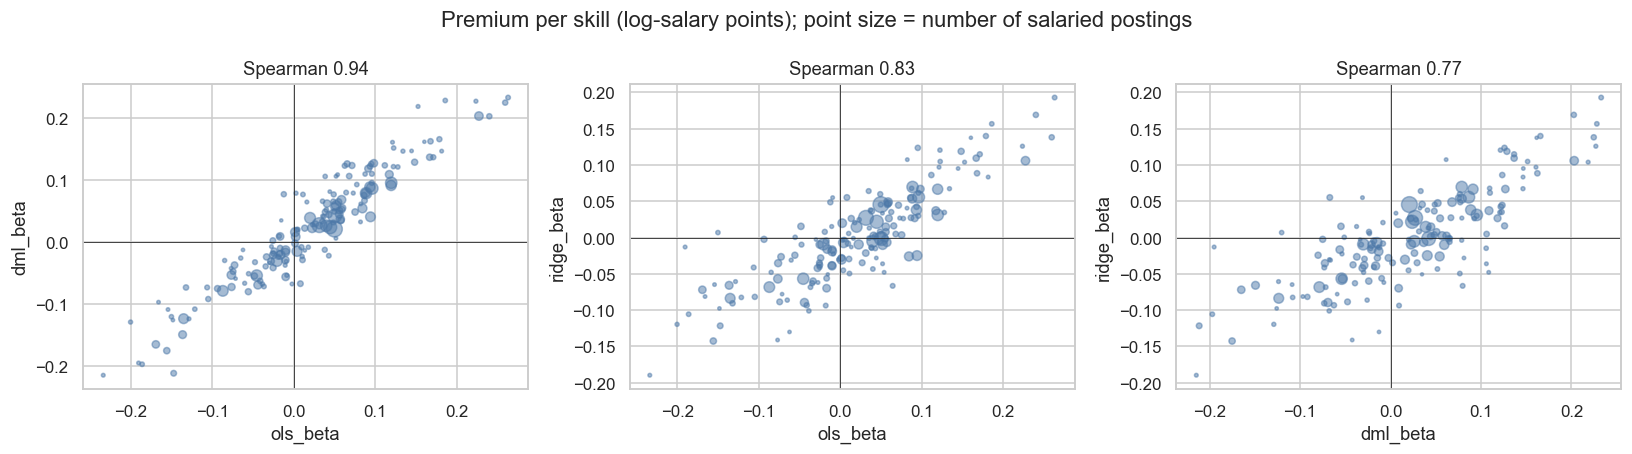

Skills where all three estimators give the same sign: 74%


In [31]:
cols = ["ols_beta", "ridge_beta", "dml_beta"]
sp = prem[cols].corr(method="spearman").round(2)
print("Rank correlation of premiums between estimators:"); display(sp)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (u, v) in zip(ax, [("ols_beta", "dml_beta"), ("ols_beta", "ridge_beta"), ("dml_beta", "ridge_beta")]):
    a.scatter(prem[u], prem[v], s=prem["n_postings"] / 6, alpha=.5, color="#4C78A8"); a.axhline(0, color="k", lw=.5); a.axvline(0, color="k", lw=.5)
    a.set_xlabel(u); a.set_ylabel(v); a.set_title(f"Spearman {prem[[u, v]].corr(method='spearman').iloc[0, 1]:.2f}")
plt.suptitle("Premium per skill (log-salary points); point size = number of salaried postings"); plt.tight_layout(); plt.show()
same_sign = (np.sign(prem["ols_beta"]) == np.sign(prem["dml_beta"]) ) & (np.sign(prem["ols_beta"]) == np.sign(prem["ridge_beta"]))
print(f"Skills where all three estimators give the same sign: {same_sign.mean():.0%}")


The three estimators rank skills alike: rank correlation 0.94 between the marginal regression and double machine learning, 0.83 with ridge, and 0.77 between ridge and double machine learning. All three give the same sign for 74% of the 170 skills. Ridge shrinks magnitudes (for `bash` it gives 0.19 against 0.26 and 0.23), as intended. Because the methods agree on ranking, the findings below do not hinge on one estimator.


## 7.5 The skills with the clearest pay association
Double machine learning is the headline estimator (it controls for the controls most flexibly). The plot shows the 12 largest positive and 12 largest negative premiums, with 95% intervals; filled points survive the 10% false-discovery control.

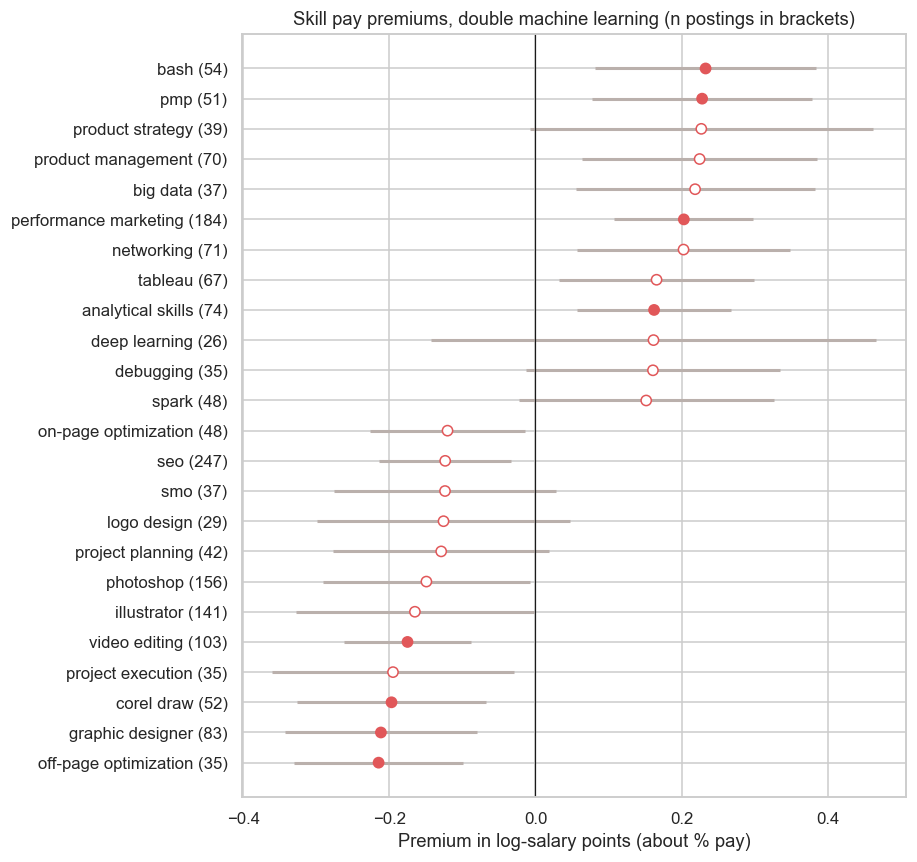

,skill,n_postings,dml_beta,dml_lo,dml_hi,dml_fdr_sig,ols_beta,ridge_beta,premium_%
146,bash,54,0.233,0.082,0.384,True,0.263,0.193,26.213
70,pmp,51,0.228,0.078,0.378,True,0.186,0.157,25.615
132,product strategy,39,0.227,-0.007,0.461,False,0.223,0.126,25.473
31,product management,70,0.225,0.063,0.386,False,0.259,0.138,25.185
106,big data,37,0.218,0.055,0.382,False,0.152,0.104,24.413
84,performance marketing,184,0.203,0.108,0.298,True,0.227,0.106,22.509
114,networking,71,0.203,0.057,0.349,False,0.240,0.169,22.458
78,tableau,67,0.166,0.032,0.300,False,0.179,0.140,18.021
77,analytical skills,74,0.162,0.057,0.268,True,0.168,0.089,17.622
108,deep learning,26,0.162,-0.143,0.466,False,0.160,0.138,17.528


,skill,n_postings,dml_beta,dml_lo,dml_hi,dml_fdr_sig,ols_beta,ridge_beta,premium_%
18,illustrator,141,-0.165,-0.328,-0.002,False,-0.169,-0.072,-15.207
96,video editing,103,-0.175,-0.261,-0.089,True,-0.156,-0.143,-16.062
111,project execution,35,-0.195,-0.360,-0.030,False,-0.191,-0.013,-17.712
76,corel draw,52,-0.197,-0.326,-0.068,True,-0.186,-0.106,-17.878
104,graphic designer,83,-0.211,-0.343,-0.080,True,-0.147,-0.122,-19.062
152,off-page optimization,35,-0.215,-0.330,-0.099,True,-0.234,-0.190,-19.318


In [32]:
prem["dml_lo"], prem["dml_hi"] = prem["dml_beta"] - 1.96 * prem["dml_se"], prem["dml_beta"] + 1.96 * prem["dml_se"]
top = pd.concat([prem.sort_values("dml_beta", ascending=False).head(12), prem.sort_values("dml_beta").head(12)]).sort_values("dml_beta")
fig, ax = plt.subplots(figsize=(8.5, 8))
yy = np.arange(len(top))
ax.hlines(yy, top["dml_lo"], top["dml_hi"], color="#BAB0AC", lw=2)
ax.scatter(top["dml_beta"], yy, c=np.where(top["dml_fdr_sig"], "#E15759", "white"), edgecolor="#E15759", s=45, zorder=3)
ax.set_yticks(yy); ax.set_yticklabels([f"{s} ({n})" for s, n in zip(top["skill"], top["n_postings"])]); ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("Premium in log-salary points (about % pay)"); ax.set_title("Skill pay premiums, double machine learning (n postings in brackets)")
plt.tight_layout(); plt.show()
show = prem.sort_values("dml_beta", ascending=False)[["skill", "n_postings", "dml_beta", "dml_lo", "dml_hi", "dml_fdr_sig", "ols_beta", "ridge_beta"]].copy()
show["premium_%"] = (np.exp(show["dml_beta"]) - 1) * 100
display(show.head(10).round(3)); display(show.tail(6).round(3))


### Reading the premiums
- **Strongest positive:** `bash` (+26%, 54 postings), `pmp` (+26%, 51), `performance marketing` (+23%, 184), `analytical skills` (+18%, 74). `product strategy`, `product management`, `big data`, `networking` and `tableau` have similar point estimates (+18% to +25%), but their intervals are wider or just touch zero.
- **Strongest negative:** `off-page optimization` (−19%), `graphic designer` (−19%), `corel draw` (−18%) and `video editing` (−16%) are the four clear ones. These are mostly **within-role contrasts**: among postings of the same role, those that list these tools pay less than those that list performance or analytics skills.
- **How much to trust it.** Typical intervals are about ±0.15 log points, so most premiums in the top ten overlap and their order is not reliable. Double machine learning finds 31 skills at p < 0.05 and **8 after false-discovery control**; the marginal regression finds 32 and 15; the ridge bootstrap finds 25 intervals excluding zero (of 170 skills).


## 7.6 Placebo check: can the method find premiums that are not there?
If salary has nothing to do with skills, a sound procedure should flag about 5% of skills at p < 0.05 and almost none after false-discovery control. To test this, postings are shuffled **within groups of the same role and experience band**, which keeps the skill mix and the pay pattern by role and experience but breaks any link between a posting's skills and its own pay. The marginal regression is repeated 300 times on shuffled data.

In [33]:
strata = (pay["role"].astype(str) + "|" + pd.qcut(pay["exp_mid"], 4, duplicates="drop").astype(str)).values
rng = np.random.RandomState(SEED); groups_idx = [np.where(strata == s)[0] for s in np.unique(strata)]
fp, nsig = [], []
for _ in range(300):
    perm = np.arange(len(pay))
    for ii in groups_idx: perm[ii] = rng.permutation(ii)
    _, _, _, pp = fwl_ols(S.values.astype(float)[perm], y, C_full, G)
    fp.append(np.mean(pp < 0.05)); nsig.append(bh(pp).sum())
print(f"Share of skills flagged at p < 0.05 on shuffled data: mean {np.mean(fp):.1%} (nominal 5%), 95th percentile {np.percentile(fp, 95):.1%}")
print(f"Skills passing the 10% false-discovery control on shuffled data: mean {np.mean(nsig):.2f}, maximum {max(nsig)}")
print(f"On the real data: {(prem['ols_p'] < .05).mean():.1%} flagged at p < 0.05 and {prem['ols_fdr_sig'].sum()} pass the false-discovery control")

Share of skills flagged at p < 0.05 on shuffled data: mean 5.7% (nominal 5%), 95th percentile 9.4%
Skills passing the 10% false-discovery control on shuffled data: mean 0.19, maximum 4
On the real data: 18.8% flagged at p < 0.05 and 15 pass the false-discovery control



On shuffled data the procedure behaves close to its claim: **5.7%** of skills are flagged at p < 0.05 (nominal 5%; the 95th percentile of runs is 9.4%), and the false-discovery control lets through **0.19** skills on average (at most 4 in any of 300 runs). On the real data **18.8%** of skills are flagged and **15** pass the control. So the real data hold far more signal than chance would produce, and the procedure is only slightly liberal. A few of the 15 may still be false positives, which is why the notebook leans on agreement across estimators and on the replication test in section 8.


## 7.7 How stable are the premiums? Estimation on 80%, 70%, 60% of the data
Premiums are estimated on a random share of **companies** (80%, 70%, 60%, and 50% for reference) and again on the remaining companies. If the premiums are real, the two sets of estimates should rank skills similarly. Rank correlation is averaged over 30 random splits per ratio; "sign agreement" is the share of skills with the same sign in both parts among those that are clearly non-zero (|t| > 2) in the larger part.

In [34]:
rows = []
Sf = S.values.astype(float)
for tr_frac in (0.8, 0.7, 0.6, 0.5):
    for rep in range(30):
        a, b = next(GroupShuffleSplit(1, test_size=1 - tr_frac, random_state=2000 + rep).split(np.zeros(len(pay)), y, groups=G))
        ok = (Sf[a].sum(0) >= 10) & (Sf[b].sum(0) >= 10)
        ba, _, ta, _ = fwl_ols(Sf[a][:, ok], y[a], C_full[a], G[a]); bb, _, _, _ = fwl_ols(Sf[b][:, ok], y[b], C_full[b], G[b])
        clear = np.abs(ta) > 2
        rows.append({"split": f"{int(tr_frac * 100)}/{int(round((1 - tr_frac) * 100))}", "spearman": stats.spearmanr(ba, bb)[0],
                     "sign_agree": (np.sign(ba[clear]) == np.sign(bb[clear])).mean() if clear.sum() >= 3 else np.nan, "skills_compared": int(ok.sum())})
st = pd.DataFrame(rows).groupby("split")[["spearman", "sign_agree", "skills_compared"]].agg(["mean", "std"]).round(2).loc[["80/20", "70/30", "60/40", "50/50"]]
st

spearman       sign_agree       skills_compared      
          mean   std       mean   std            mean   std
split                                                      
80/20     0.28  0.08       0.75  0.08          121.17  7.59
70/30     0.28  0.07       0.76  0.08          152.53  5.09
60/40     0.29  0.06       0.80  0.09          166.00  1.62
50/50     0.30  0.06       0.75  0.09          168.90  0.96


### Reading the stability result
Premiums estimated on one set of companies correlate only weakly with premiums on the other set: rank correlation **0.28** (80/20), **0.28** (70/30), **0.29** (60/40) and **0.30** (50/50). Among skills that are clearly non-zero in the larger part, the sign agrees in **75% to 80%** of cases. The correlation does not rise as the smaller part grows from 20% to 50% of the companies, which suggests the weak agreement comes from genuinely small, noisy premiums and not just from a small test share. In plain terms: the largest premiums replicate in sign, the ranking of the rest does not, and no list of skills should be presented as a precise league table.


## 7.8 Controls ablation: how much of a raw skill premium is just experience and role?
The same marginal regression with progressively more controls. A premium that shrinks sharply when experience is added was mostly a signal of seniority.

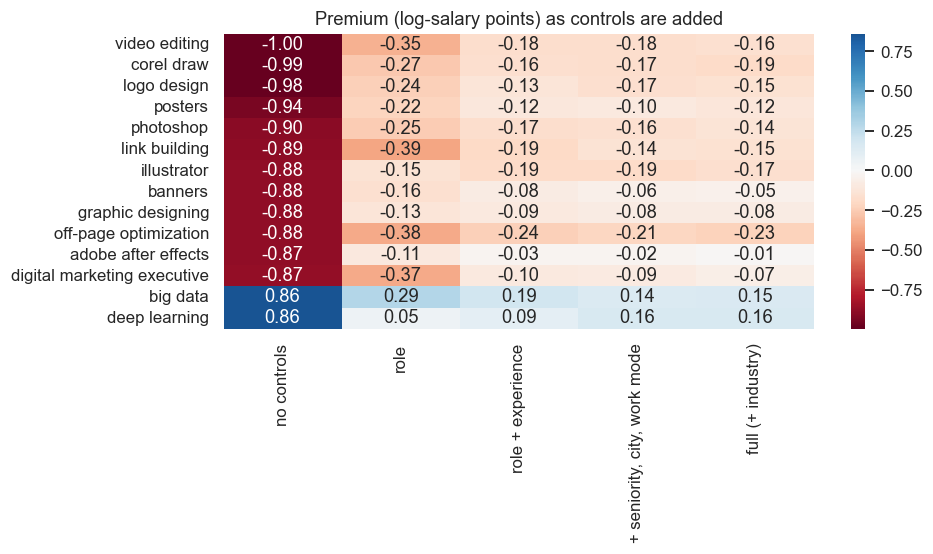

Among skills with a raw premium above 0.2 log points (150), the median share left after full controls: 12%


In [35]:
sets = {"no controls": [], "role": ["role"], "role + experience": ["exp", "role"],
        "+ seniority, city, work mode": ["exp", "role", "seniority", "city", "work_mode"], "full (+ industry)": ["exp", "role", "seniority", "city", "work_mode", "industry_g"]}
cab = {}
for name, parts in sets.items():
    C = ctrl_ols(parts) if parts else np.ones((len(pay), 1))
    cab[name] = fwl_ols(S.values.astype(float), y, C, G)[0]
cab = pd.DataFrame(cab, index=S.columns)
pick = cab["no controls"].abs().sort_values(ascending=False).head(14).index
plt.figure(figsize=(9, 5.2)); sns.heatmap(cab.loc[pick], annot=True, fmt=".2f", cmap="RdBu", center=0); plt.title("Premium (log-salary points) as controls are added")
plt.tight_layout(); plt.show()
shrink = (cab["full (+ industry)"].abs() / cab["no controls"].abs()).loc[cab["no controls"].abs() > 0.2]
print(f"Among skills with a raw premium above 0.2 log points ({len(shrink)}), the median share left after full controls: {shrink.median():.0%}")


Raw skill pay gaps are mostly seniority and role in disguise. Without controls, 150 of the 170 skills show a premium above 0.2 log points. Once experience, role, seniority, city, work mode and industry are controlled, the **median skill keeps only 12%** of its raw premium. The heatmap shows how each premium changes as controls are added. Any comparison of "pay of postings asking for skill X" with the average posting overstates the value of the skill several times over.


## 7.9 Topic premiums
The same marginal regression for the LDA topics: each topic's share is standardised, so the premium is the pay difference for a posting one standard deviation higher in that topic's share, with the full controls.

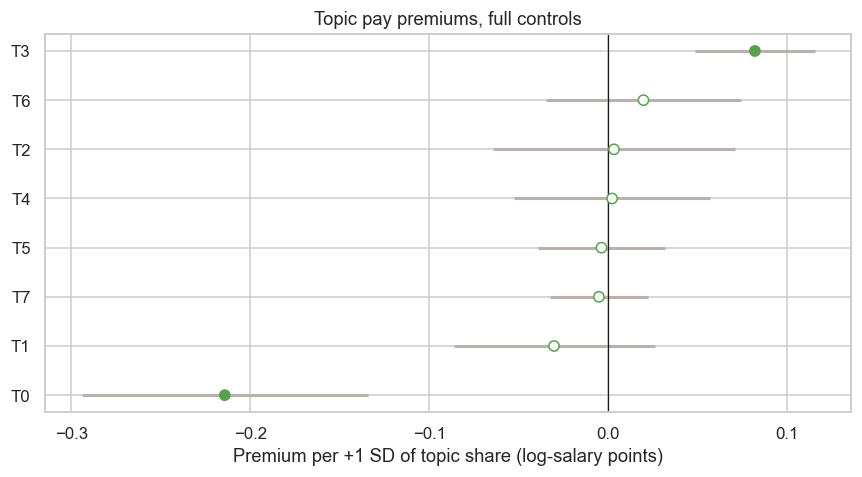

,topic,beta_per_SD,lo,hi,p,top words,fdr_sig
3,T3,0.082,0.048,0.115,0.000,"product, analytics, s, working, ai, insights, ...",True
6,T6,0.020,-0.035,0.074,0.481,"details, latest, disclaimer, applying, directl...",False
2,T2,0.003,-0.065,0.071,0.928,"cloud, infrastructure, security, devops, azure...",False
4,T4,0.002,-0.053,0.057,0.940,"ai, engineering, learning, models, solutions, ...",False
5,T5,-0.004,-0.039,0.031,0.830,"software, applications, code, technologies, sy...",False
7,T7,-0.005,-0.033,0.022,0.705,"solutions, time, education, project, software,...",False
1,T1,-0.030,-0.086,0.026,0.289,"project, product, delivery, stakeholders, supp...",False
0,T0,-0.214,-0.294,-0.134,0.000,"marketing, digital, seo, media, social, campai...",True


In [36]:
Th = topics(); Thz = (Th - Th.mean(0)) / Th.std(0)
bt, st_, tt, pt = fwl_ols(Thz, y, C_full, G)
tp = pd.DataFrame({"topic": [f"T{k}" for k in range(Thz.shape[1])], "beta_per_SD": bt, "lo": bt - 1.96 * st_, "hi": bt + 1.96 * st_, "p": pt,
                   "top words": [", ".join(words[np.argsort(-LDA[K_TOPIC].components_[k])[:7]]) for k in range(Thz.shape[1])]})
tp["fdr_sig"] = bh(tp["p"].values)
tp = tp.sort_values("beta_per_SD", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5)); yy = np.arange(len(tp))[::-1]
ax.hlines(yy, tp["lo"], tp["hi"], color="#BAB0AC", lw=2); ax.scatter(tp["beta_per_SD"], yy, c=np.where(tp["fdr_sig"], "#59A14F", "white"), edgecolor="#59A14F", s=45, zorder=3)
ax.set_yticks(yy); ax.set_yticklabels(tp["topic"]); ax.axvline(0, color="k", lw=.8); ax.set_xlabel("Premium per +1 SD of topic share (log-salary points)"); ax.set_title("Topic pay premiums, full controls")
plt.tight_layout(); plt.show()
tp.round(3)


Two of the eight topics have a clear association with pay after controls, and the other six have intervals that include zero. **Topic 3** (product, analytics, AI, insights) goes with **+0.08 log points** (about +8%) per standard deviation of topic share (95% interval 0.05 to 0.12). **Topic 0** (marketing, digital, SEO, social media, campaigns) goes with **−0.21** (about −19%; interval −0.29 to −0.13): within the same role, postings written mostly in marketing language pay less than comparable postings that are not. The boilerplate topic (Topic 6) comes out at +0.02 with an interval including zero, which is the right answer for a topic with no job content and a useful check on the method.


# 8. Evaluation on Held-out Postings

The 20% of companies set aside in section 4.1 are used here for the first time. Two questions:

1. **Do text-mining features improve prediction of unseen companies' pay?** Models are fitted on the training part and scored on the test part.
2. **Do premiums estimated on the training part hold up on the test part?** Skills are selected on the training postings only (false-discovery control), then their premiums are re-estimated on the test postings.

In [37]:
# skills selected on training postings only
Str = S.values.astype(float)[tr_i]
ok = (Str.sum(0) >= 15)
b_tr, _, _, p_tr = fwl_ols(Str[:, ok], y[tr_i], C_full[tr_i], G[tr_i])
sel_names = S.columns[ok][bh(p_tr, 0.20)]
print(f"Skills selected on the training part (false-discovery rate 20%): {len(sel_names)} -> {list(sel_names)[:12]}")
X_sel = fs(S[sel_names].values.astype(float)) if len(sel_names) else fs()
tests = {"F0 controls only": X_SETS["F0 controls only"], "controls + selected skills": X_sel,
         "F3 + skills (tag or text)": X_SETS["F3 + skills (tag or text)"], "F4 + topics": X_SETS["F4 + topics"], "F7 + all text features": X_SETS["F7 + skills, topics, SVD, clusters"]}
rows = {}
for name, X in tests.items():
    for l in ("Ridge", "XGBoost"):
        m = LEARNERS[l]().fit(X[tr_i], y[tr_i]); pr = m.predict(X[te_i])
        rows[(name, l)] = {"R2_test": r2_score(y[te_i], pr), "MAE_INR": float(np.mean(np.abs(np.exp(pr) - np.exp(y[te_i]))))}
ev = pd.DataFrame(rows).T; ev.index.names = ["feature set", "learner"]
ev.style.format({"R2_test": "{:.3f}", "MAE_INR": "{:,.0f}"})

Skills selected on the training part (false-discovery rate 20%): 28 -> ['agile', 'analytics', 'seo', 'photoshop', 'illustrator', 'java', 'product management', 'scrum', 'adobe creative suite', 'pmp', 'corel draw', 'analytical skills']


Selected skills: sign agreement train vs test 71%; Spearman 0.23


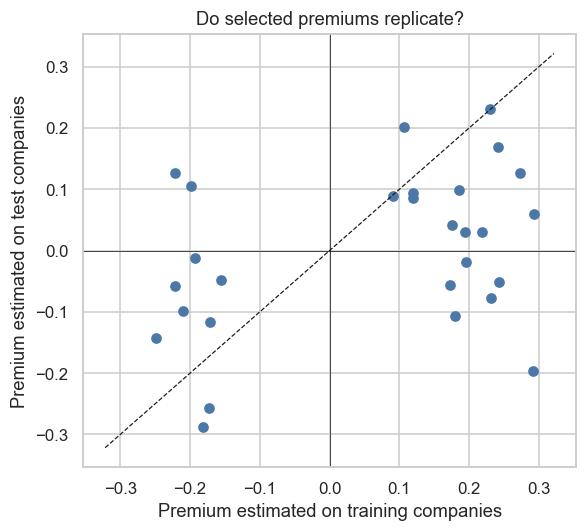

In [38]:
if len(sel_names) >= 3:
    j = [list(S.columns).index(s) for s in sel_names]
    b_te, _, t_te, _ = fwl_ols(S.values.astype(float)[te_i][:, j], y[te_i], C_full[te_i], G[te_i])
    b_tr2 = fwl_ols(S.values.astype(float)[tr_i][:, j], y[tr_i], C_full[tr_i], G[tr_i])[0]
    cmp_ = pd.DataFrame({"skill": sel_names, "premium_train": b_tr2, "premium_test": b_te}).set_index("skill")
    print(f"Selected skills: sign agreement train vs test {np.mean(np.sign(cmp_['premium_train']) == np.sign(cmp_['premium_test'])):.0%}; Spearman {stats.spearmanr(cmp_['premium_train'], cmp_['premium_test'])[0]:.2f}")
    plt.figure(figsize=(5.5, 5)); plt.scatter(cmp_["premium_train"], cmp_["premium_test"], color="#4C78A8"); lim = max(cmp_.abs().max()) * 1.1; plt.plot([-lim, lim], [-lim, lim], "k--", lw=.8); plt.axhline(0, color="k", lw=.5); plt.axvline(0, color="k", lw=.5)
    plt.xlabel("Premium estimated on training companies"); plt.ylabel("Premium estimated on test companies"); plt.title("Do selected premiums replicate?"); plt.tight_layout(); plt.show()
    cmp_.round(3)


### Reading the held-out results
- **Prediction of unseen companies' pay barely changes with text-mining features.** On the 267 test postings from 204 unseen companies, controls only give R² 0.685 (Ridge) and 0.714 (XGBoost). Adding the skills selected on the training part gives 0.695 and 0.723 (+0.010 and +0.009); topics give 0.688 and 0.722; all skills give 0.671 and 0.726; all text features together give 0.667 and 0.714. The gains are at most about 0.012 and change sign across learners.
- **Selected premiums replicate only partly.** For the 28 skills selected on the training companies (false-discovery rate 20%), the sign of the premium on the test companies agrees for **71%**, with rank correlation **0.23**. The test part is small (267 postings), which limits this check, but it agrees with the stability result: modest evidence for a few skills, not for a ranking.


# 9. Role Fit from the Description

**The question.** Can the description alone tell which of the 10 roles a posting is for, and how much of that signal is just the role's name appearing in the text?

**Labels.** The role comes from the posting title (section 1), so the description is a separate piece of evidence. That separation is not perfect: descriptions often repeat the title ("We are hiring a Data Analyst..."). A high score could therefore be reading the name and not the content. Section 9.4 tests this directly by removing the role-naming words, and by cutting the text to its first 200 to 1,000 characters.

**Protocol.** 80% train and 20% test, split **by company** so no employer is on both sides (the test is used once, in 9.8). Model comparison is 5-fold company-grouped cross-validation on the training part. The main metric is **macro-F1** (the average of the 10 per-role F1 scores), because the roles are unbalanced: Digital Marketing is about 24% of postings and Data Scientist about 5%. Accuracy is shown beside it.

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

RC = corp[["text", "title", "role", "company_key"]].copy()
CLASSES = list(RC["role"].astype("category").cat.categories)
yc = RC["role"].astype("category").cat.codes.values
Gc = RC["company_key"].values
tr_c, te_c = next(GroupShuffleSplit(1, test_size=0.2, random_state=SEED).split(RC, yc, groups=Gc))
assert not set(Gc[tr_c]) & set(Gc[te_c])
print(f"Train {len(tr_c):,} postings ({len(set(Gc[tr_c])):,} companies) | test {len(te_c):,} postings ({len(set(Gc[te_c])):,} companies)")
print((RC["role"].value_counts(normalize=True) * 100).round(1).to_string())

Train 8,716 postings (4,548 companies) | test 2,064 postings (1,137 companies)
role
Digital Marketing          18.2
Software Engineer          14.5
Project Manager            11.9
Graphic Designer           10.8
DevOps / Cloud Engineer     9.2
Business Analyst            8.5
Product Manager             7.3
Data Engineer               7.3
Data Scientist              6.9
Data Analyst                5.4


In [40]:
def _take(X, idx):
    return X.iloc[idx] if hasattr(X, "iloc") else X[idx]

def cv_clf(make, X, idx=tr_c, n=5):
    f1s, accs = [], []
    for a, b in GroupKFold(n).split(np.zeros(len(idx)), yc[idx], groups=Gc[idx]):
        m = make().fit(_take(X, idx[a]), yc[idx[a]]); p = m.predict(_take(X, idx[b]))
        f1s.append(f1_score(yc[idx[b]], p, average="macro")); accs.append(accuracy_score(yc[idx[b]], p))
    return {"macro_F1": np.mean(f1s), "F1_sd": np.std(f1s), "accuracy": np.mean(accs)}

def tfidf(**kw):
    p = dict(token_pattern=TOKEN, stop_words="english", min_df=5, max_df=0.5, sublinear_tf=True); p.update(kw)
    return TfidfVectorizer(**p)
fmt = {"macro_F1": "{:.3f}", "F1_sd": "{:.3f}", "accuracy": "{:.3f}"}
print("Utilities ready")

Utilities ready


## 9.1 Models on the description text
Six classifiers on TF-IDF of the full description (unigrams): a majority-class baseline, Complement naive Bayes, logistic regression, linear SVM, ridge classifier and SGD with the modified Huber loss. Then four classifiers on **dense text-mining features** (the 50 SVD dimensions, the 8 LDA topic shares and the 12-cluster membership from section 3): k-nearest neighbours (cosine), random forest, XGBoost and a small neural network. TF-IDF is refitted inside each fold.

,macro_F1,F1_sd,accuracy
Logistic regression,0.890,0.007,0.908
Linear SVM,0.889,0.008,0.908
Ridge classifier,0.883,0.008,0.902
SGD (modified Huber),0.880,0.005,0.900
"XGBoost, text-mining features",0.874,0.010,0.894
"MLP, text-mining features",0.866,0.011,0.889
"Random forest, text-mining features",0.866,0.018,0.888
"k-NN (cosine), text-mining features",0.839,0.008,0.865
Complement naive Bayes,0.829,0.005,0.854
Majority class,0.030,0.002,0.178


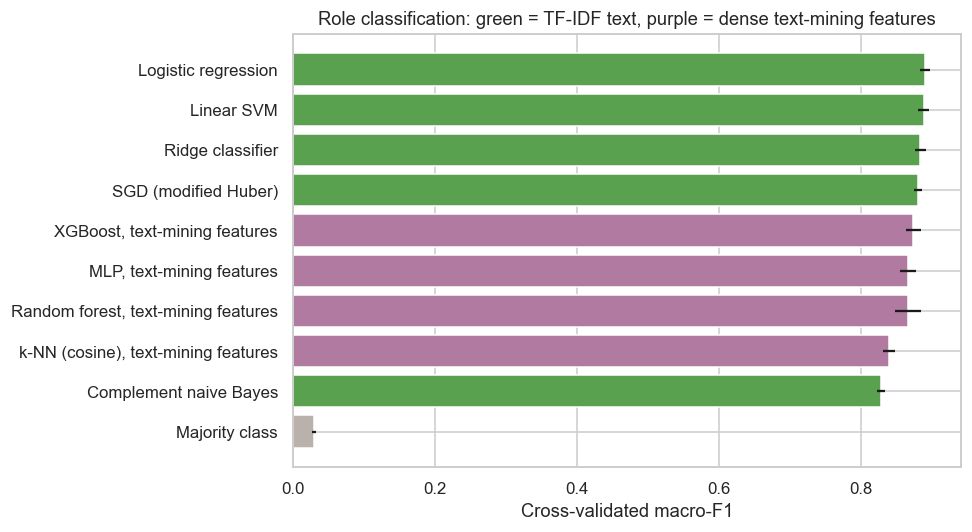

Best by macro-F1: Logistic regression


In [41]:
TEXT_MODELS = {
    "Majority class": lambda: make_pipeline(tfidf(), DummyClassifier(strategy="most_frequent")),
    "Complement naive Bayes": lambda: make_pipeline(tfidf(), ComplementNB(alpha=0.3)),
    "Logistic regression": lambda: make_pipeline(tfidf(), LogisticRegression(C=10, max_iter=300, class_weight="balanced")),
    "Linear SVM": lambda: make_pipeline(tfidf(), LinearSVC(C=0.5, class_weight="balanced")),
    "Ridge classifier": lambda: make_pipeline(tfidf(), RidgeClassifier(alpha=1.0, class_weight="balanced")),
    "SGD (modified Huber)": lambda: make_pipeline(tfidf(), SGDClassifier(loss="modified_huber", alpha=1e-4, class_weight="balanced", random_state=SEED)),
}
DENSE = np.hstack([Z, THETA[K_TOPIC], pd.get_dummies(corp["cluster"]).values.astype(float)])
DENSE_MODELS = {
    "k-NN (cosine), text-mining features": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(15, metric="cosine", weights="distance")),
    "Random forest, text-mining features": lambda: RandomForestClassifier(300, min_samples_leaf=2, class_weight="balanced", n_jobs=-1, random_state=SEED),
    "XGBoost, text-mining features": lambda: XGBClassifier(n_estimators=200, learning_rate=0.08, max_depth=4, subsample=0.8, colsample_bytree=0.6, n_jobs=-1, random_state=SEED, verbosity=0),
    "MLP, text-mining features": lambda: make_pipeline(StandardScaler(), MLPClassifier((64,), alpha=1e-2, early_stopping=True, max_iter=500, random_state=SEED)),
}
rc = {}
for k, mk in TEXT_MODELS.items(): rc[k] = cv_clf(mk, RC["text"])
for k, mk in DENSE_MODELS.items(): rc[k] = cv_clf(mk, DENSE)
rcdf = pd.DataFrame(rc).T.sort_values("macro_F1", ascending=False)
display(rcdf.style.format(fmt))
plt.figure(figsize=(9, 5)); plt.barh(rcdf.index, rcdf["macro_F1"], xerr=rcdf["F1_sd"], color=["#BAB0AC" if "Majority" in i else ("#59A14F" if "features" not in i else "#B07AA1") for i in rcdf.index])
plt.gca().invert_yaxis(); plt.xlabel("Cross-validated macro-F1"); plt.title("Role fit: green = TF-IDF text, purple = dense text-mining features"); plt.tight_layout(); plt.show()
BEST_CLF = rcdf.drop("Majority class").index[0]; print("Best by macro-F1:", BEST_CLF)


### Reading the model comparison
- **Every real model is far above the baseline.** The majority-class guess scores macro-F1 0.030 (accuracy 0.178); the best models reach about 0.89 (accuracy 0.91).
- **Linear models on TF-IDF lead and are tied.** Logistic regression (0.890) and the linear SVM (0.889) are within the fold spread (about 0.007) of each other and of the ridge classifier (0.883) and SGD (0.880).
- **A compact representation keeps most of the signal.** The 70 dense text-mining columns (SVD, topics, clusters) give 0.874 with XGBoost, within 0.02 of the full text, so most of what identifies a role survives compression into topics and clusters.
- **Weaker:** the MLP and random forest on those features (0.866), k-NN (0.839) and Complement naive Bayes (0.829).


## 9.2 How the text is represented
One factor at a time, using the linear SVM: unigrams against unigrams plus bigrams, binary presence against TF-IDF weights, no stop-word removal, vocabulary size, and the minimum number of postings a word must appear in.

In [42]:
svm = lambda **kw: (lambda: make_pipeline(tfidf(**kw), LinearSVC(C=0.5, class_weight="balanced")))
variants = {
    "reference (unigrams, TF-IDF, df >= 5)": svm(),
    "unigrams + bigrams": svm(ngram_range=(1, 2), max_features=60000),
    "binary presence (no counts)": svm(binary=True, use_idf=False),
    "raw term frequency (no IDF, no log)": svm(use_idf=False, sublinear_tf=False),
    "keep stop words": svm(stop_words=None),
    "vocabulary 1,000 words": svm(max_features=1000),
    "vocabulary 5,000 words": svm(max_features=5000),
    "vocabulary 20,000 words": svm(max_features=20000),
    "words in at least 20 postings": svm(min_df=20),
}
rr = pd.DataFrame({k: cv_clf(mk, RC["text"]) for k, mk in variants.items()}).T
display(rr.style.format(fmt))

,macro_F1,F1_sd,accuracy
"reference (unigrams, TF-IDF, df >= 5)",0.889,0.008,0.908
unigrams + bigrams,0.909,0.013,0.924
binary presence (no counts),0.885,0.009,0.904
"raw term frequency (no IDF, no log)",0.888,0.009,0.906
keep stop words,0.888,0.007,0.907
"vocabulary 1,000 words",0.888,0.009,0.906
"vocabulary 5,000 words",0.888,0.008,0.907
"vocabulary 20,000 words",0.889,0.008,0.908
words in at least 20 postings,0.888,0.008,0.907



Only **bigrams** clearly help: unigrams plus bigrams reach macro-F1 0.909 against 0.889 (+0.020, larger than the fold spread of 0.008 to 0.013). Phrases such as "project management" or "power bi" carry role information that single words split. Everything else is within 0.004 of the reference: binary presence, raw frequency, keeping stop words, vocabularies from 1,000 to 20,000 words, or a stricter document-frequency cut. A vocabulary of just 1,000 words already gives 0.888, so role identification does not depend on rare words.


## 9.3 Does the model read the role's name or the content? Text length x masking
Two stress tests combined in one grid, with the linear SVM:

- **Text length:** only the first 200, 500 or 1,000 characters, or the full description. The 500-character row is what the old data limit allowed.
- **Masking:** *none*; **role words** (every word that names a role, such as analyst, engineer, manager, designer, data, software, marketing, removed from all texts); **title words** (every word of the posting's own title removed from its own description). The last is the strictest: whatever the title says cannot be used.

If the score stays high when the role-naming words are gone, the description carries real content about the job.

Share of descriptions containing at least one word of their own title: 93.9%


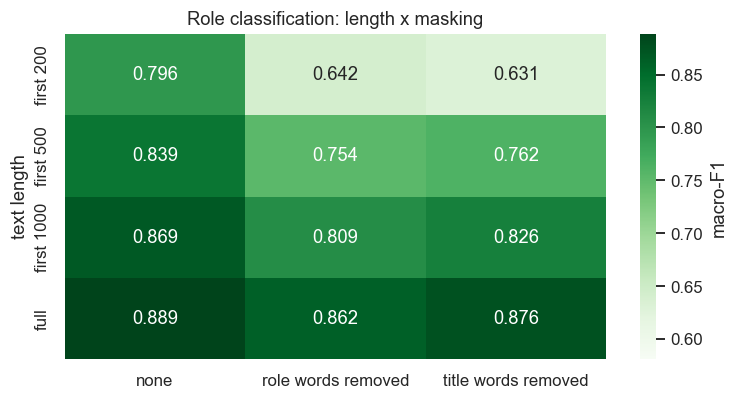

,none,role words removed,title words removed
first 200,0.796,0.642,0.631
first 500,0.839,0.754,0.762
first 1000,0.869,0.809,0.826
full,0.889,0.862,0.876


In [43]:
ROLE_WORDS = {"software", "engineer", "engineers", "engineering", "developer", "developers", "sde", "data", "analyst", "analysts", "analytics", "analysis", "scientist",
              "science", "devops", "cloud", "business", "product", "project", "program", "programme", "manager", "management", "digital", "marketing", "graphic",
              "designer", "design", "scrum", "master", "etl", "seo", "sre", "reliability", "machine", "learning", "ml"}
def mask_words(t): return " ".join(w for w in re.findall(TOKEN, t) if w not in ROLE_WORDS)
def mask_title(t, title):
    tt = set(re.findall(TOKEN, title.lower()))
    return " ".join(w for w in re.findall(TOKEN, t) if w not in tt)
MASKED = {"none": RC["text"], "role words removed": RC["text"].map(mask_words),
          "title words removed": pd.Series([mask_title(t, ti) for t, ti in zip(RC["text"], RC["title"])], index=RC.index)}
own = np.mean([len(set(re.findall(TOKEN, ti.lower())) & set(re.findall(TOKEN, t))) > 0 for t, ti in zip(RC["text"], RC["title"])])
print(f"Share of descriptions containing at least one word of their own title: {own:.1%}")
LENS = [200, 500, 1000, None]
grid = {}
for mname, ser in MASKED.items():
    for L in LENS:
        X = ser if L is None else (RC["text"].str.slice(0, L) if mname == "none" else ser.str.slice(0, L * 0 + 10**9))
        if L is not None and mname != "none":
            base = RC["text"].str.slice(0, L)
            X = base.map(mask_words) if mname == "role words removed" else pd.Series([mask_title(t, ti) for t, ti in zip(base, RC["title"])], index=RC.index)
        grid[(mname, "full" if L is None else f"first {L}")] = cv_clf(svm(), X)["macro_F1"]
g = pd.Series(grid).unstack(0)[list(MASKED)].loc[[f"first {L}" for L in LENS[:-1]] + ["full"]]
plt.figure(figsize=(7, 3.8)); sns.heatmap(g, annot=True, fmt=".3f", cmap="Greens", vmin=g.values.min() - 0.05, cbar_kws={"label": "macro-F1"}); plt.ylabel("text length"); plt.title("Role fit: length x masking"); plt.tight_layout(); plt.show()
g.round(3)


### Does the model read the role's name or the job's content?
- **The name is in the text but not what the model relies on.** 93.9% of descriptions contain at least one word of their own title, yet removing every role-naming word lowers macro-F1 only from 0.889 to 0.862 (−0.027), and removing each posting's own title words lowers it to 0.876 (−0.013). Most of the signal is content: tools, duties and skills.
- **Length matters a lot.** With only the first 500 characters the score falls to 0.839 (−0.050), and with 200 characters to 0.796. When role-naming words are also removed, 500 characters give 0.754 against 0.862 for the full text (−0.108). So the old 500-character limit would have clearly hurt role fit, in contrast to pay prediction, where truncating the text made no difference (section 6.4).


## 9.4 Which kind of evidence identifies the role
The same question with different inputs: the full text, only the employer's skill tags, the dense text-mining features (SVD, topics, clusters), and text plus tags together. Run with the title words removed as well, to see which representations survive without the name.

In [44]:
TAGX = T.astype(float).values
TXT_TITLE = MASKED["title words removed"]
DF_TT = pd.DataFrame(TAGX, columns=[f"tag{i}" for i in range(TAGX.shape[1])]); DF_TT["text"] = RC["text"].values
DF_TT_M = DF_TT.copy(); DF_TT_M["text"] = TXT_TITLE.values
def text_plus_tags():
    ct = ColumnTransformer([("t", tfidf(), "text"), ("g", "passthrough", [f"tag{i}" for i in range(TAGX.shape[1])])])
    return make_pipeline(ct, LinearSVC(C=0.5, class_weight="balanced"))
rows = {
    "full text (TF-IDF, linear SVM)": (cv_clf(svm(), RC["text"]), cv_clf(svm(), TXT_TITLE)),
    "employer skill tags only (linear SVM)": (cv_clf(lambda: LinearSVC(C=0.5, class_weight="balanced"), TAGX),) * 2,
    "text-mining features (logistic regression)": (cv_clf(lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=500, class_weight="balanced")), DENSE),) * 2,
    "text + tags (linear SVM)": (cv_clf(text_plus_tags, DF_TT), cv_clf(text_plus_tags, DF_TT_M)),
}
ft = pd.DataFrame({k: {"macro_F1": v[0]["macro_F1"], "F1_sd": v[0]["F1_sd"], "macro_F1 (title words removed)": v[1]["macro_F1"]} for k, v in rows.items()}).T
ft.loc["text-mining features (logistic regression)", "macro_F1 (title words removed)"] = np.nan
ft.loc["employer skill tags only (linear SVM)", "macro_F1 (title words removed)"] = np.nan
ft.style.format("{:.3f}", na_rep="n/a: input does not contain the title")

,macro_F1,F1_sd,macro_F1 (title words removed)
"full text (TF-IDF, linear SVM)",0.889,0.008,0.876
employer skill tags only (linear SVM),0.801,0.015,n/a: input does not contain the title
text-mining features (logistic regression),0.874,0.015,n/a: input does not contain the title
text + tags (linear SVM),0.906,0.007,0.904



The employer's skill tags alone identify the role well (macro-F1 0.801), the dense text-mining features reach 0.874 and the full text 0.889. The two views are complementary: **text plus tags gives 0.906**, a gain of 0.017 over text alone (the fold spread is 0.007), and it holds when the title words are removed (0.904 against 0.876 for text alone). Skills listed by the employer add information the wording does not carry, mainly for roles that share vocabulary.


## 9.5 Handling unbalanced roles: class weights

In [45]:
cw = {}
for name, mk in {"Linear SVM": lambda w: make_pipeline(tfidf(), LinearSVC(C=0.5, class_weight=w)),
                 "Logistic regression": lambda w: make_pipeline(tfidf(), LogisticRegression(C=10, max_iter=300, class_weight=w))}.items():
    for w in (None, "balanced"):
        cw[(name, "balanced" if w else "none")] = cv_clf(lambda: mk(w), RC["text"])
pd.DataFrame(cw).T.style.format(fmt)


Class weighting makes no difference (linear SVM 0.890 unweighted against 0.889 balanced; logistic regression 0.888 against 0.890). The roles are unbalanced (Digital Marketing 18%, Data Analyst 5%) but separable enough that the large classes do not crowd out the small ones; the per-role scores in 9.7 confirm that.


## 9.6 Train/test split ratio
The comparison repeated with 80/20, 70/30 and 60/40 company-grouped splits, 5 random splits each: the share of companies used for training changes, and each model is scored on the rest. Three inputs are compared (full text, text with title words removed, skill tags only).

split,80/20,70/30,60/40
input,,,
"full text, Complement NB",0.832,0.835,0.837
"full text, linear SVM",0.884,0.887,0.888
"skill tags only, linear SVM",0.809,0.806,0.805
"title words removed, linear SVM",0.876,0.880,0.878


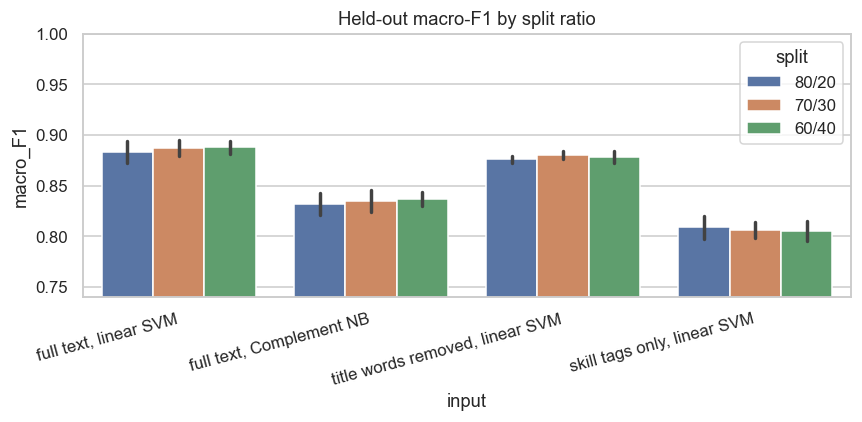

In [46]:
recs = []
for tr_frac in (0.8, 0.7, 0.6):
    for rep in range(5):
        a, b = next(GroupShuffleSplit(1, test_size=1 - tr_frac, random_state=3000 + rep).split(RC, yc, groups=Gc))
        for name, X, mk in [("full text, linear SVM", RC["text"], svm()), ("full text, Complement NB", RC["text"], TEXT_MODELS["Complement naive Bayes"]),
                            ("title words removed, linear SVM", TXT_TITLE, svm()), ("skill tags only, linear SVM", TAGX, lambda: LinearSVC(C=0.5, class_weight="balanced"))]:
            p = mk().fit(_take(X, a), yc[a]).predict(_take(X, b))
            recs.append((f"{int(tr_frac * 100)}/{int(round((1 - tr_frac) * 100))}", name, f1_score(yc[b], p, average="macro")))
R2 = pd.DataFrame(recs, columns=["split", "input", "macro_F1"])
tbl = R2.groupby(["input", "split"])["macro_F1"].agg(["mean", "std"]).round(3)
display(tbl["mean"].unstack("split")[["80/20", "70/30", "60/40"]].style.format("{:.3f}"))
plt.figure(figsize=(8, 4)); sns.barplot(data=R2, x="input", y="macro_F1", hue="split", errorbar="sd"); plt.xticks(rotation=15, ha="right"); plt.ylim(R2["macro_F1"].min() - 0.05, 1); plt.title("Held-out macro-F1 by split ratio"); plt.tight_layout(); plt.show()


The result does not depend on the split ratio. The linear SVM scores 0.884, 0.887 and 0.888 at 80/20, 70/30 and 60/40; with title words removed 0.876, 0.880 and 0.878; skill tags alone 0.809, 0.806 and 0.805; Complement naive Bayes 0.832, 0.835 and 0.837. Training on 60% of the companies is already enough (differences of at most 0.004), and the ranking of the inputs is the same at every ratio.


## 9.7 Final model on the test companies
The linear SVM on the full-text TF-IDF is refitted on the whole training part and scored once on the held-out companies. A second model is trained and tested with the title words removed, as the harder, more honest version.

,accuracy,macro-F1
majority class,0.198,0.033
full text,0.897,0.881
title words removed,0.896,0.881


,F1 full text,F1 title words removed,test postings
Data Analyst,0.792,0.824,126
Business Analyst,0.797,0.834,206
Data Engineer,0.849,0.842,143
Product Manager,0.857,0.829,143
Software Engineer,0.857,0.849,214
Data Scientist,0.886,0.875,134
Project Manager,0.901,0.893,272
DevOps / Cloud Engineer,0.928,0.924,164
Graphic Designer,0.971,0.967,253
Digital Marketing,0.974,0.972,409


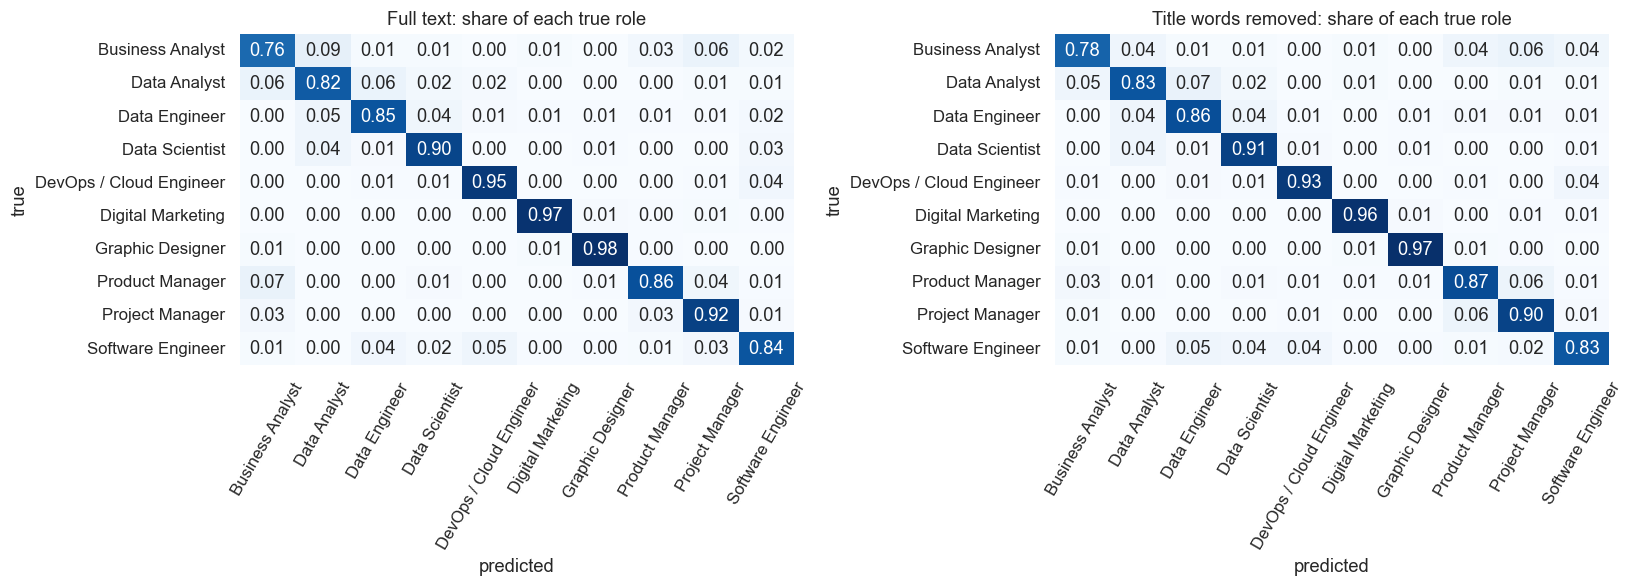

In [47]:
final = svm()().fit(RC["text"].iloc[tr_c], yc[tr_c]); pf = final.predict(RC["text"].iloc[te_c])
final_m = svm()().fit(TXT_TITLE.iloc[tr_c], yc[tr_c]); pm = final_m.predict(TXT_TITLE.iloc[te_c])
base_p = np.full(len(te_c), np.bincount(yc[tr_c]).argmax())
summ = pd.DataFrame({"majority class": [accuracy_score(yc[te_c], base_p), f1_score(yc[te_c], base_p, average="macro")],
                     "full text": [accuracy_score(yc[te_c], pf), f1_score(yc[te_c], pf, average="macro")],
                     "title words removed": [accuracy_score(yc[te_c], pm), f1_score(yc[te_c], pm, average="macro")]}, index=["accuracy", "macro-F1"]).T
display(summ.style.format("{:.3f}"))
per = pd.DataFrame({"F1 full text": f1_score(yc[te_c], pf, average=None), "F1 title words removed": f1_score(yc[te_c], pm, average=None),
                    "test postings": np.bincount(yc[te_c], minlength=len(CLASSES))}, index=CLASSES).sort_values("F1 full text")
display(per.style.format({"F1 full text": "{:.3f}", "F1 title words removed": "{:.3f}"}))
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, p, t in zip(ax, (pf, pm), ("Full text", "Title words removed")):
    cm = confusion_matrix(yc[te_c], p, normalize="true"); sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=a, cbar=False); a.set_title(f"{t}: share of each true role"); a.set_xlabel("predicted"); a.set_ylabel("true")
    a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()


### Reading the test result
- On the **2,064 test postings from 1,137 companies the model never saw**, the full-text model reaches accuracy 0.897 and macro-F1 0.881, against 0.198 and 0.033 for the majority class.
- The model trained **without the title words** scores the same (accuracy 0.896, macro-F1 0.881), so the performance is not an artefact of the role's name appearing in the text.
- **Easiest roles:** Digital Marketing (F1 0.974) and Graphic Designer (0.971), which have very distinctive tools and vocabulary (SEO, Photoshop, Illustrator). DevOps / Cloud is next (0.928) and Project Manager 0.901.
- **Hardest:** Data Analyst (0.792) and Business Analyst (0.797); with title words removed they rise to 0.824 and 0.834, a sign that the title words were pulling these two towards each other.


## 9.8 What words identify each role, and where the model errs

In [48]:
vec, svc = final.steps[0][1], final.steps[1][1]
names = np.array(vec.get_feature_names_out())
vecm, svcm = final_m.steps[0][1], final_m.steps[1][1]; names_m = np.array(vecm.get_feature_names_out())
rows = {CLASSES[k]: (", ".join(names[np.argsort(-svc.coef_[k])[:7]]), ", ".join(names_m[np.argsort(-svcm.coef_[k])[:7]])) for k in range(len(CLASSES))}
RC_WORDS = dict(rows)
pd.DataFrame(rows, index=["top words, full text", "top words, title words removed"]).T

,"top words, full text","top words, title words removed"
Business Analyst,"analyst, analysis, requirements, process, gath...","data, analysis, gathering, processes, ba, proc..."
Data Analyst,"analyst, data, reports, spreadsheets, sql, cli...","reports, analytics, sql, dashboards, dataset, ..."
Data Engineer,"data, engineer, etl, pyspark, big, engineering...","pyspark, engineering, pipelines, migrate, tran..."
Data Scientist,"scientist, ml, models, learning, model, scienc...","models, model, science, ml, ai/ml, python, mac..."
DevOps / Cloud Engineer,"devops, cloud, infrastructure, deployment, sre...","infrastructure, deployment, kubernetes, terraf..."
Digital Marketing,"marketing, seo, digital, search, content, meta...","campaigns, content, seo, search, keyword, stra..."
Graphic Designer,"designer, visual, illustrator, graphic, photos...","photoshop, illustrator, designs, creative, ado..."
Product Manager,"product, owner, roadmap, products, manager, fe...","roadmap, products, business, features, analyst..."
Project Manager,"project, program, manager, delivery, scrum, ma...","management, pmp, product, projects, programs, ..."
Software Engineer,"software, developer, c, applications, angular,...","applications, c, development, data, code, debu..."


In [49]:
cm = confusion_matrix(yc[te_c], pf); np.fill_diagonal(cm, 0)
pairs = sorted([(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(len(CLASSES)) for j in range(len(CLASSES)) if cm[i, j] > 0], reverse=True)[:8]
print("Most frequent confusions on the test companies (count, true role -> predicted role):")
for c_, a_, b_ in pairs: print(f"  {c_:3d}  {a_} -> {b_}")
wrong = RC.iloc[te_c][pf != yc[te_c]].assign(pred=[CLASSES[i] for i in pf[pf != yc[te_c]]])[["title", "role", "pred"]]
wrong.sample(10, random_state=SEED)

Most frequent confusions on the test companies (count, true role -> predicted role):
   18  Business Analyst -> Data Analyst
   13  Business Analyst -> Project Manager
   10  Software Engineer -> DevOps / Cloud Engineer
   10  Product Manager -> Business Analyst
    8  Software Engineer -> Data Engineer
    8  Project Manager -> Product Manager
    8  Project Manager -> Business Analyst
    8  Data Analyst -> Data Engineer


,title,role,pred
1879,Business Analyst,Business Analyst,Software Engineer
8600,Senior Software Engineer,Software Engineer,Project Manager
6997,Product Owner,Product Manager,Graphic Designer
4135,Business Analyst,Business Analyst,Project Manager
3411,Immediate Opening For Data Engineer,Data Engineer,Data Scientist
10622,Client Technology -Senior Product Delivery Man...,Project Manager,Product Manager
2735,Data Engineer,Data Engineer,Data Analyst
8909,Senior Data Analyst,Data Analyst,Data Engineer
927,Digital Marketing and Communication Manager (B2B),Digital Marketing,Graphic Designer
5378,Product /Program Manager - Supply Chain,Project Manager,Business Analyst



The errors are between **neighbouring roles with overlapping duties**: Business Analyst taken for Data Analyst (18 cases) or Project Manager (13), Software Engineer for DevOps (10) or Data Engineer (8), Product Manager for Business Analyst (10), Project Manager for Product Manager (8) or Business Analyst (8), Data Analyst for Data Engineer (8). Some errors are really label noise: the role comes from the title, and a posting titled "Immediate Opening For Data Engineer" can describe work a classifier reads as Data Scientist, so a perfect score is not possible. The top words per role are sensible (Graphic Designer: Photoshop, Illustrator; DevOps: Kubernetes, Terraform; Data Engineer: PySpark, pipelines) and, with the title words removed, move from the name of the role to its tools.


## 9.9 Who states the pay? Classifying a posting's pay disclosure from its wording

Everything that uses salary rests on the postings that **state** one, about one in eight. Whether a posting states its pay is a text-classification problem in its own right, and a new one: the label is a behaviour of the employer, not a topic or a job title. This section trains on **all** role-matched postings (every posting has a yes or no label), compares models and text representations, and reads off which words and phrases separate employers who state pay from those who stay silent.

- **Why it matters.** Batra, Michaud and Mongey (2023), *Online Job Posts Contain Very Little Wage Information* (NBER w31984, forthcoming in Labour Economics), find that about 14% of US posts carry any wage, that disclosure is concentrated in few firms and follows the occupation-wage gradient, and that high-wage firms are more opaque. Hazell and Taska (2025, *American Economic Review*) use posted wages for the same reason. We found no study that predicts disclosure from the wording of a posting, and none for India.
- **Metrics.** The rate is low (12.9%), so accuracy alone flatters: saying "does not state" for every posting scores 87.1%. We report ROC-AUC and average precision, and accuracy, precision, recall and F1 for the "states pay" class at a threshold chosen on the scores of the other folds. Every result is five-fold cross-validation grouped by company.
- **Leakage.** A description that names a salary would give the answer away, so amounts, "CTC", "LPA" and "salary" are removed from the text first, and one run keeps them to show the difference.

In [50]:
SAL_PAT = r"(?:₹|\brs\.?|\binr)\s*[\d,.]+|\b\d[\d,.]*\s*(?:lpa|lakhs?|lacs?|ctc|per annum|p\.a\.)|\b(?:salary|ctc|compensation|stipend|remuneration|lpa)\b"
corp["disclosed"] = (corp["salary_disclosed"] & corp["salary_min"].notna() & corp["salary_max"].notna()).values
mentions = corp["text"].map(lambda t: bool(re.search(SAL_PAT, t, re.I)))
print(f"{corp['disclosed'].sum():,} of {len(corp):,} role-matched postings state a salary ({corp['disclosed'].mean():.1%}); saying 'does not state' every time is right {1 - corp['disclosed'].mean():.1%} of the time")
print(f"Descriptions that mention salary, CTC or an amount: {mentions[corp['disclosed']].mean():.1%} of disclosing postings, {mentions[~corp['disclosed']].mean():.1%} of the rest")
corp["text_ns"] = corp["text"].map(lambda t: re.sub(SAL_PAT, " ", t, flags=re.I))
corp["n_tags"] = corp["tags"].map(len); corp["len_chars"] = corp["text"].str.len()
yd = corp["disclosed"].astype(int).values; Gd = corp["company_key"].values

1,389 of 10,780 role-matched postings state a salary (12.9%); saying 'does not state' every time is right 87.1% of the time
Descriptions that mention salary, CTC or an amount: 15.0% of disclosing postings, 5.8% of the rest


### 9.9.1 Which model reads disclosure best?
Seven models on the description words (salary figures removed) and on posting attributes. The attributes are role, seniority, city, industry, years asked, number of skill tags and text length.

,ROC-AUC,average precision,accuracy,precision,recall,F1,macro-F1
Logistic regression (words + attributes),0.882,0.491,0.835,0.415,0.688,0.518,0.709
Logistic regression (words),0.871,0.478,0.849,0.440,0.629,0.518,0.714
Linear SVM (words),0.863,0.477,0.848,0.435,0.598,0.504,0.707
MLP (100 SVD components of the words),0.851,0.460,0.833,0.404,0.623,0.490,0.695
Complement naive Bayes (words),0.839,0.426,0.835,0.399,0.546,0.461,0.682
XGBoost (attributes),0.819,0.410,0.808,0.351,0.575,0.435,0.660
Logistic regression (role only),0.593,0.162,0.506,0.157,0.649,0.253,0.442
Say 'does not state' every time,0.500,0.129,0.871,0.000,0.000,0.000,0.466


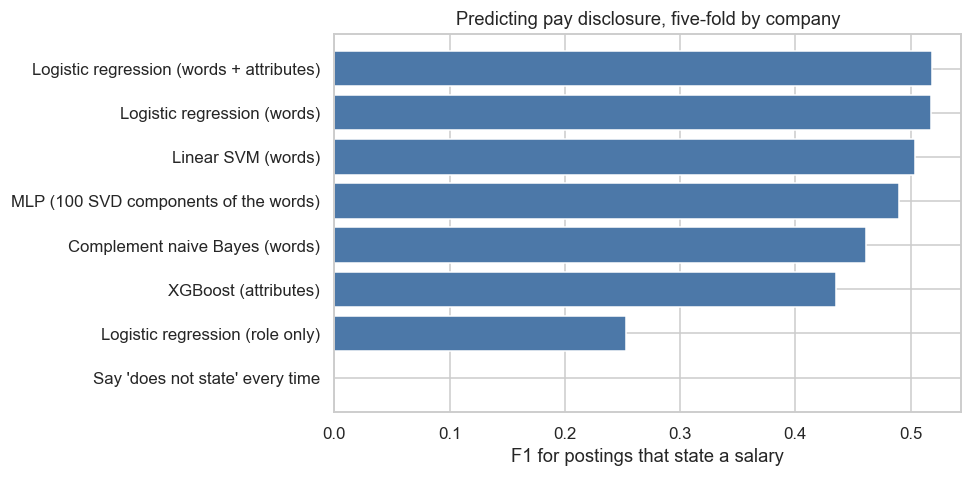

In [51]:
from scipy.sparse import csr_matrix, hstack
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import accuracy_score, average_precision_score, precision_recall_curve, precision_score, recall_score, roc_auc_score
from sklearn.naive_bayes import ComplementNB
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import LinearSVC
CATS = ["role", "seniority", "city", "industry_g"]; NUMS = ["exp_mid", "n_tags", "len_chars"]
FOLDS = list(GroupKFold(5).split(corp, yd, groups=Gd))
def X_text_kw(**kw):
    p = dict(token_pattern=TOKEN, stop_words="english", min_df=5, max_df=0.5, sublinear_tf=True, max_features=5000); p.update(kw)
    def f(A, B, col): v = TfidfVectorizer(**p); return v.fit_transform(A[col]), v.transform(B[col])
    return f
X_text = X_text_kw()
def X_struct(A, B, col):
    oh = OneHotEncoder(handle_unknown="ignore").fit(A[CATS]); sc = StandardScaler().fit(A[NUMS])
    f = lambda D: hstack([oh.transform(D[CATS]), csr_matrix(sc.transform(D[NUMS]))]).tocsr(); return f(A), f(B)
def X_both(A, B, col):
    ta, tb = X_text(A, B, col); sa, sb = X_struct(A, B, col); return hstack([ta, sa]).tocsr(), hstack([tb, sb]).tocsr()
def X_role(A, B, col):
    oh = OneHotEncoder(handle_unknown="ignore").fit(A[["role"]]); return oh.transform(A[["role"]]), oh.transform(B[["role"]])
def X_svd(A, B, col):
    ta, tb = X_text(A, B, col); s = TruncatedSVD(100, random_state=SEED).fit(ta); sc = StandardScaler().fit(s.transform(ta)); return sc.transform(s.transform(ta)), sc.transform(s.transform(tb))
def score_of(m, X): return m.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X)
def oof_run(feat, make_model, col="text_ns"):
    out = np.zeros(len(corp))
    for a, b in FOLDS:
        Xa, Xb = feat(corp.iloc[a], corp.iloc[b], col); out[b] = score_of(make_model().fit(Xa, yd[a]), Xb)
    return out
def best_thr(p, y):
    pr, rc, th = precision_recall_curve(y, p); f = 2 * pr * rc / np.maximum(pr + rc, 1e-9); return th[np.argmax(f[:-1])]
def report(p):
    yh = np.zeros(len(p), int)
    for a, b in FOLDS: yh[b] = (p[b] >= best_thr(p[a], yd[a])).astype(int)   # threshold taken from the other folds' scores
    return {"ROC-AUC": roc_auc_score(yd, p), "average precision": average_precision_score(yd, p), "accuracy": accuracy_score(yd, yh), "precision": precision_score(yd, yh), "recall": recall_score(yd, yh), "F1": f1_score(yd, yh), "macro-F1": f1_score(yd, yh, average="macro")}
LR = lambda C: (lambda: LogisticRegression(C=C, max_iter=600))
XGB = lambda: XGBClassifier(n_estimators=250, learning_rate=0.06, max_depth=4, subsample=0.8, colsample_bytree=0.7, n_jobs=-1, random_state=SEED, verbosity=0)
MODELS = {
    "Complement naive Bayes (words)": (X_text, lambda: ComplementNB(alpha=0.3)),
    "Logistic regression (words)": (X_text, LR(3)),
    "Linear SVM (words)": (X_text, lambda: LinearSVC(C=0.3)),
    "MLP (100 SVD components of the words)": (X_svd, lambda: MLPClassifier((64,), alpha=1e-2, early_stopping=True, max_iter=400, random_state=SEED)),
    "Logistic regression (role only)": (X_role, LR(1)),
    "XGBoost (attributes)": (X_struct, XGB),
    "Logistic regression (words + attributes)": (X_both, LR(1)),
}
OOF = {k: oof_run(f, m) for k, (f, m) in MODELS.items()}
dz_rows = {k: report(p) for k, p in OOF.items()}
dz_rows["Say 'does not state' every time"] = {"ROC-AUC": 0.5, "average precision": yd.mean(), "accuracy": 1 - yd.mean(), "precision": 0.0, "recall": 0.0, "F1": 0.0, "macro-F1": f1_score(yd, np.zeros_like(yd), average="macro")}
dis_tbl = pd.DataFrame(dz_rows).T.sort_values("F1", ascending=False)
display(dis_tbl.style.format("{:.3f}"))
plt.figure(figsize=(9, 4.5)); plt.barh(dis_tbl.index[::-1], dis_tbl["F1"][::-1], color=["#BAB0AC" if "every time" in k else "#4C78A8" for k in dis_tbl.index[::-1]]); plt.xlabel("F1 for postings that state a salary"); plt.title("Predicting pay disclosure, five-fold by company"); plt.tight_layout(); plt.show()
BEST = "Logistic regression (words)"; THR_BEST = float(np.mean([best_thr(OOF[BEST][a], yd[a]) for a, b in FOLDS]))

**Finding.** Only 12.9% of postings state a salary, so saying "does not state" every time is 87.1% accurate and finds nothing; accuracy is not the score to read. On F1 for the postings that do state pay, logistic regression on the description words leads (F1 0.518, precision 0.44, recall 0.63, ROC-AUC 0.871), with the linear SVM close behind (0.504), then the neural network on 100 SVD components (0.490), Complement naive Bayes (0.461) and XGBoost on posting attributes alone (0.435). The role by itself is barely better than chance (ROC-AUC 0.593, F1 0.253). Adding attributes to the words gains almost nothing (F1 0.518, ROC-AUC 0.882). The signal is in the wording.

### 9.9.2 How should the text be represented? Ablations
The logistic regression on description words, changing one thing at a time: the weighting, adding two-word phrases, vocabulary size, stop words, and leaving salary figures in the text.

In [52]:
dz_variants = {
    "reference (unigrams, TF-IDF, 5,000 words)": (X_text, "text_ns"),
    "unigrams + bigrams": (X_text_kw(ngram_range=(1, 2), max_features=40000), "text_ns"),
    "binary presence (no counts)": (X_text_kw(binary=True, use_idf=False), "text_ns"),
    "raw term frequency (no IDF, no log)": (X_text_kw(use_idf=False, sublinear_tf=False), "text_ns"),
    "keep stop words": (X_text_kw(stop_words=None), "text_ns"),
    "vocabulary 1,000 words": (X_text_kw(max_features=1000), "text_ns"),
    "vocabulary 20,000 words": (X_text_kw(max_features=20000), "text_ns"),
    "words in at least 20 postings": (X_text_kw(min_df=20), "text_ns"),
    "salary figures left in the text": (X_text, "text"),
}
dis_repr = pd.DataFrame({k: report(oof_run(f, LR(3), col)) for k, (f, col) in dz_variants.items()}).T[["ROC-AUC", "average precision", "precision", "recall", "F1"]]
display(dis_repr.style.format("{:.3f}"))

,ROC-AUC,average precision,precision,recall,F1
"reference (unigrams, TF-IDF, 5,000 words)",0.871,0.478,0.440,0.629,0.518
unigrams + bigrams,0.882,0.514,0.455,0.616,0.523
binary presence (no counts),0.871,0.476,0.453,0.598,0.515
"raw term frequency (no IDF, no log)",0.867,0.475,0.431,0.628,0.511
keep stop words,0.871,0.481,0.435,0.646,0.520
"vocabulary 1,000 words",0.864,0.462,0.403,0.661,0.501
"vocabulary 20,000 words",0.873,0.485,0.449,0.621,0.521
words in at least 20 postings,0.870,0.477,0.435,0.615,0.510
salary figures left in the text,0.873,0.489,0.452,0.635,0.528


In [53]:
def X_svd_k(k):
    def f(A, B, col):
        ta, tb = X_text(A, B, col); s = TruncatedSVD(k, random_state=SEED).fit(ta); return s.transform(ta), s.transform(tb)
    return f
dz_exp = {"logistic regression on the words (reference)": (X_text, LR(3)),
          "balanced class weights": (X_text, lambda: LogisticRegression(C=3, max_iter=600, class_weight="balanced")),
          "SVD 50 components, then logistic regression": (X_svd_k(50), LR(1)),
          "SVD 100 components, then logistic regression": (X_svd_k(100), LR(1)),
          "SVD 200 components, then logistic regression": (X_svd_k(200), LR(1)),
          "SVD 100 components, then XGBoost": (X_svd_k(100), XGB)}
dis_svd = pd.DataFrame({k: report(oof_run(f, m)) for k, (f, m) in dz_exp.items()}).T[["ROC-AUC", "average precision", "precision", "recall", "F1"]]
display(dis_svd.style.format("{:.3f}"))

,ROC-AUC,average precision,precision,recall,F1
logistic regression on the words (reference),0.871,0.478,0.440,0.629,0.518
balanced class weights,0.871,0.473,0.426,0.641,0.512
"SVD 50 components, then logistic regression",0.869,0.467,0.410,0.670,0.509
"SVD 100 components, then logistic regression",0.873,0.481,0.432,0.641,0.516
"SVD 200 components, then logistic regression",0.876,0.495,0.425,0.662,0.518
"SVD 100 components, then XGBoost",0.865,0.477,0.405,0.613,0.488


**Finding.** The representation hardly matters. Across nine variants F1 stays between 0.501 and 0.528 and ROC-AUC between 0.864 and 0.882; two-word phrases give the highest ROC-AUC and average precision (0.882, 0.514), and a vocabulary of only 1,000 words costs a little recall-adjusted F1 (0.501). Leaving the salary figures in the text changes almost nothing (F1 0.528 against 0.518), so the model is not reading a number. The same holds when the train share changes: ROC-AUC is 0.859 to 0.866 from an 80/20 to a 50/50 split, so more training postings would not help much. Compressing the words first does not help either: logistic regression after a 50, 100 or 200-component SVD of the TF-IDF matrix scores F1 0.509, 0.516 and 0.518 (ROC-AUC 0.869, 0.873, 0.876), no better than the plain words (0.518, 0.871), and SVD followed by XGBoost is lower (0.488). Balanced class weights also leave F1 unchanged (0.512). The plain TF-IDF words are used.

### 9.9.3 How much of the description is needed, and how much training data?
Text length matters for the pay analysis (a 500-character limit hides skills). Here the same model reads the first 200, 500 or 1,000 characters, or the whole description. Then the train/test split ratio is varied (repeated grouped splits, 5 each).

In [54]:
len_rows = {}
for L in (200, 500, 1000, None):
    corp["t_len"] = corp["text_ns"] if L is None else corp["text_ns"].str.slice(0, L)
    len_rows["full" if L is None else f"first {L} characters"] = report(oof_run(X_text, LR(3), "t_len"))
dis_len = pd.DataFrame(len_rows).T[["ROC-AUC", "average precision", "precision", "recall", "F1"]]
display(dis_len.style.format("{:.3f}"))
sp_rows = []
for ts in (0.2, 0.3, 0.4, 0.5):
    au, ap = [], []
    for k in range(5):
        a, b = next(GroupShuffleSplit(1, test_size=ts, random_state=SEED + k).split(corp, yd, groups=Gd))
        Xa, Xb = X_text(corp.iloc[a], corp.iloc[b], "text_ns"); p = LR(3)().fit(Xa, yd[a]).predict_proba(Xb)[:, 1]
        au.append(roc_auc_score(yd[b], p)); ap.append(average_precision_score(yd[b], p))
    sp_rows.append({"split (train/test)": f"{round((1 - ts) * 100)}/{round(ts * 100)}", "ROC-AUC": np.mean(au), "AUC sd": np.std(au), "average precision": np.mean(ap), "AP sd": np.std(ap)})
dis_split = pd.DataFrame(sp_rows).set_index("split (train/test)")
display(dis_split.style.format("{:.3f}"))

,ROC-AUC,average precision,precision,recall,F1
first 200 characters,0.767,0.342,0.310,0.527,0.390
first 500 characters,0.792,0.386,0.349,0.534,0.422
first 1000 characters,0.819,0.426,0.397,0.515,0.449
full,0.871,0.478,0.440,0.629,0.518


,ROC-AUC,AUC sd,average precision,AP sd
split (train/test),,,,
80/20,0.859,0.011,0.483,0.034
70/30,0.866,0.009,0.482,0.023
60/40,0.861,0.011,0.472,0.023
50/50,0.859,0.004,0.463,0.017


**Finding.** Length matters a great deal. Reading only the first 500 characters gives F1 0.422 and ROC-AUC 0.792, against 0.518 and 0.871 for the whole description; 200 characters gives 0.390. The cues that separate disclosing from silent postings sit late in the text, in the closing boilerplate, which is the part a 500-character snippet drops.

### 9.9.4 Which words and phrases separate disclosing from silent postings?
A classifier says how well; this says why. The weighted log-odds ratio with an informative Dirichlet prior (Monroe, Colaresi and Quinn 2008, *Fightin' Words*, Political Analysis 16) compares the word counts of postings that state a salary with those that do not, shrinking rare words toward the overall rate. A larger positive score means the word or phrase leans toward disclosure; negative means toward silence.

In [55]:
from sklearn.feature_extraction.text import CountVectorizer
def fightin(ngram, min_df, a0=500.0, top=15):
    cv = CountVectorizer(token_pattern=TOKEN, stop_words="english", ngram_range=ngram, min_df=min_df, max_df=0.5); Xc = cv.fit_transform(corp["text_ns"]); voc = cv.get_feature_names_out()
    y1, y0 = Xc[yd == 1].sum(0).A1, Xc[yd == 0].sum(0).A1; prior = Xc.sum(0).A1; aw = a0 * prior / prior.sum(); n1, n0 = y1.sum(), y0.sum()
    delta = np.log((y1 + aw) / (n1 + a0 - y1 - aw)) - np.log((y0 + aw) / (n0 + a0 - y0 - aw)); z = delta / np.sqrt(1 / (y1 + aw) + 1 / (y0 + aw))
    o = np.argsort(z); mk = lambda ids: [{"term": voc[i], "z": float(z[i]), "states": int(y1[i]), "silent": int(y0[i])} for i in ids]
    return mk(o[::-1][:top]), mk(o[:top])
uni_yes, uni_no = fightin((1, 1), 30); bi_yes, bi_no = fightin((2, 2), 30)
print("Leaning toward stating pay (words):  ", ", ".join(f"{d['term']} ({d['z']:.1f})" for d in uni_yes[:12]))
print("Leaning toward silence (words):      ", ", ".join(f"{d['term']} ({d['z']:.1f})" for d in uni_no[:12]))
print("Leaning toward stating pay (phrases):", ", ".join(f"{d['term']} ({d['z']:.1f})" for d in bi_yes[:10]))
print("Leaning toward silence (phrases):    ", ", ".join(f"{d['term']} ({d['z']:.1f})" for d in bi_no[:10]))

Leaning toward stating pay (words):   marketing (39.1), ads (34.7), campaign (32.4), meta (29.9), google (26.6), campaigns (26.4), conversion (25.7), digital (24.9), profile (24.1), lead (23.7), performance (23.4), creatives (21.4)
Leaning toward silence (words):       information (-18.9), latest (-16.7), change (-16.4), solutions (-16.3), directly (-16.3), software (-16.0), source (-15.9), details (-15.3), external (-15.3), availability (-15.1), subject (-14.6), posting (-14.5)
Leaning toward stating pay (phrases): candidate profile (26.5), lead generation (26.1), meta ads (25.7), performance marketing (24.4), google ads (23.8), digital marketing (22.3), role responsibilities (21.9), preferred candidate (21.6), social media (21.1), ads meta (17.7)
Leaning toward silence (phrases):     company website (-11.7), role details (-9.9), years time (-8.3), time education (-8.3), directly company (-8.0), job posting (-8.0), project role (-7.7), disclaimer job (-7.3), good skills (-7.2), softwa

**Finding.** Two kinds of signal. Marketing and advertising vocabulary leans toward stating pay (marketing, ads, campaign, meta, google, conversion; phrases such as "meta ads", "performance marketing", "lead generation"). This is the role effect: Digital Marketing postings state pay most often (19.5%). Boilerplate leans toward silence ("company website", "role details", "job posting", "disclaimer job", "directly company", and the words information, latest, details, external, subject). That wording belongs to agencies and templated postings that say little about the job, which fits disclosure being a habit of the employer more than a feature of the role.

### 9.9.5 Who discloses? Roles, experience and firms
The text signal could be an employer habit rather than a property of the job. Counting by company and by role shows how much.

In [56]:
fgrp = corp.groupby("company_key")["disclosed"].agg(["size", "sum", "mean"])
never_share = float((corp["company_key"].map(fgrp["sum"]) == 0).mean()); multi = fgrp[fgrp["size"] >= 5]; disclosers = corp[corp["disclosed"]]
print(f"{len(fgrp):,} companies; {len(multi):,} with at least 5 postings. Median company states a salary in {fgrp['mean'].median():.0%} of its postings.")
print(f"{never_share:.1%} of postings come from companies that never state a salary in this data.")
print(f"{(disclosers['company_key'].map(fgrp['mean']) >= 0.5).mean():.1%} of the salary-stating postings come from companies that state one in at least half of their postings.")
print(f"Among companies with at least 5 postings: {(multi['sum'] == 0).mean():.1%} never state a salary, {(multi['mean'] >= 0.5).mean():.1%} state one in at least half of their postings.")
def share_by(col, bins=None):
    s = corp[col] if bins is None else pd.cut(corp[col], bins)
    return corp.groupby(s)["disclosed"].agg(["mean", "size"]).rename(columns={"mean": "share", "size": "postings"})
by_role = share_by("role").sort_values("share"); by_sen = share_by("seniority"); by_exp = share_by("exp_mid", [-1, 2, 5, 8, 12, 40]); by_city = share_by("city").sort_values("share")
display(by_role.style.format({"share": "{:.1%}"})); display(by_exp.style.format({"share": "{:.1%}"}))

5,685 companies; 260 with at least 5 postings. Median company states a salary in 0% of its postings.
76.5% of postings come from companies that never state a salary in this data.
85.5% of the salary-stating postings come from companies that state one in at least half of their postings.
Among companies with at least 5 postings: 67.7% never state a salary, 8.5% state one in at least half of their postings.


,share,postings
role,,
Software Engineer,5.6%,1561
Business Analyst,8.9%,917
Data Scientist,9.9%,748
Product Manager,11.1%,787
Data Engineer,11.2%,784
Project Manager,13.4%,1281
Graphic Designer,15.0%,1163
DevOps / Cloud Engineer,15.1%,993
Data Analyst,15.8%,584


,share,postings
exp_mid,,
"(-1, 2]",11.6%,1731
"(2, 5]",13.4%,3333
"(5, 8]",12.7%,3196
"(8, 12]",13.7%,1744
"(12, 40]",12.8%,776


**Finding.** Disclosure is concentrated in a few employers. 76.5% of postings come from companies that never state a salary in this data, and 85.5% of the salary-stating postings come from companies that state one in at least half of their postings. Among the 260 companies with at least five postings, 67.7% never state pay and 8.5% state it most of the time. By role, Software Engineer postings state pay least (5.6%) and Digital Marketing most (19.5%); experience and seniority matter little (11.6% to 13.7% across experience bands). This matches what Batra, Michaud and Mongey report for the US: few firms, and a pattern along the occupation-wage gradient.

### 9.9.6 So what for the salary results? A selection check
Two short checks, kept descriptive. First, the pay the description points to, for every posting (a ridge model on the salary-stating postings, scored out-of-fold by company for them): do employers that stay silent point to different pay inside the same role? Second, how far would the role medians move if each salary-stating posting were weighted by how unlikely it was to state pay? Weighting corrects only for what the text and attributes show.

In [57]:
from sklearn.linear_model import Ridge
payidx = np.where(corp["disclosed"].values & corp.index.isin(pay.index))[0]
pay_rows = corp.iloc[payidx]; ypay = np.log((pay_rows["salary_min"].astype(float).values + pay_rows["salary_max"].astype(float).values) / 2)
def pay_X(A):
    v = TfidfVectorizer(token_pattern=TOKEN, stop_words="english", min_df=5, max_df=0.5, sublinear_tf=True, max_features=3000)
    oh = OneHotEncoder(handle_unknown="ignore").fit(A[["role", "seniority", "city"]]); sc = StandardScaler().fit(A[["exp_mid"]])
    f = lambda D, t: hstack([t, oh.transform(D[["role", "seniority", "city"]]), csr_matrix(sc.transform(D[["exp_mid"]]))]).tocsr()
    ta = v.fit_transform(A["text_ns"]); return f(A, ta), (lambda D: f(D, v.transform(D["text_ns"])))
pred = np.full(len(corp), np.nan); others = np.setdiff1d(np.arange(len(corp)), payidx); acc = np.zeros(len(others)); k_ = 0
for a, b in GroupKFold(5).split(pay_rows, ypay, groups=pay_rows["company_key"].values):
    XA, tf = pay_X(pay_rows.iloc[a]); m = Ridge(alpha=3.0).fit(XA, ypay[a])
    pred[payidx[b]] = m.predict(tf(pay_rows.iloc[b])); acc += m.predict(tf(corp.iloc[others])); k_ += 1
pred[others] = acc / k_; corp["pred_pay"] = np.exp(pred) / 1e5
dsel = corp.assign(group=np.where(corp["disclosed"], "states a salary", "does not")).groupby(["role", "group"])["pred_pay"].median().unstack()
dsel["gap_pct"] = (dsel["does not"] / dsel["states a salary"] - 1) * 100
overall = {g_: float(corp.loc[(corp["disclosed"]) == (g_ == "states a salary"), "pred_pay"].median()) for g_ in ("states a salary", "does not")}
w_ = corp.loc[~corp["disclosed"], "role"].value_counts(normalize=True); adj_gap = float((dsel["gap_pct"] * w_.reindex(dsel.index).fillna(0)).sum())
rng_ = np.random.default_rng(SEED); comps = corp["company_key"].unique(); cidx = {c: np.where(corp["company_key"].values == c)[0] for c in comps}
def adj_gap_of(dz_rows):
    d = corp.iloc[dz_rows]; m_ = d.assign(gr=np.where(d["disclosed"], "y", "n")).groupby(["role", "gr"])["pred_pay"].median().unstack()
    if not {"y", "n"} <= set(m_.columns): return np.nan
    gap = (m_["n"] / m_["y"] - 1) * 100; wt = d.loc[~d["disclosed"], "role"].value_counts(normalize=True).reindex(gap.index).fillna(0); return float((gap * wt).sum())
boot = [adj_gap_of(np.concatenate([cidx[c] for c in rng_.choice(comps, len(comps))])) for _ in range(150)]
lo_, hi_ = np.nanpercentile(boot, [2.5, 97.5])
display(dsel.round(2))
print(f"Median pay the text points to: ₹{overall['states a salary']:.1f} L for postings that state a salary, ₹{overall['does not']:.1f} L for those that do not.")
print(f"Gap inside roles, weighted by the non-disclosing postings: {adj_gap:+.1f}% (company bootstrap 95% interval {lo_:+.1f}% to {hi_:+.1f}%)")
p_hat = np.clip(OOF[BEST], 0, None); p_hat = np.clip(1 / (1 + np.exp(-OOF[BEST])) if OOF[BEST].min() < 0 else OOF[BEST], 0.02, 1.0)
wts = 1 / p_hat[payidx]; wts = np.minimum(wts, np.quantile(wts, 0.95))
def wmedian(v, w):
    o = np.argsort(v); c = np.cumsum(w[o]); return v[o][np.searchsorted(c, 0.5 * c[-1])]
mid_all = (pay_rows["salary_min"].astype(float).values + pay_rows["salary_max"].astype(float).values) / 2 / 1e5; rows_ = []
for r_ in CORE_ROLES:
    m_ = pay_rows["role"].values == r_
    if m_.sum() < 20: continue
    raw_, wt_ = float(np.median(mid_all[m_])), float(wmedian(mid_all[m_], wts[m_])); rows_.append({"role": r_, "n": int(m_.sum()), "raw median": raw_, "weighted median": wt_, "shift %": (wt_ / raw_ - 1) * 100})
ipw = pd.DataFrame(rows_).set_index("role"); ess = float(wts.sum() ** 2 / (wts ** 2).sum()); display(ipw.round(2))
print(f"Effective sample size after weighting: {ess:,.0f} of {len(wts):,}")

group,does not,states a salary,gap_pct
role,,,
Business Analyst,10.06,9.68,3.95
Data Analyst,8.12,7.20,12.80
Data Engineer,15.57,15.81,-1.58
Data Scientist,19.56,20.78,-5.84
DevOps / Cloud Engineer,12.60,13.91,-9.42
Digital Marketing,4.11,4.94,-16.81
Graphic Designer,4.05,3.99,1.34
Product Manager,17.87,17.52,2.00
Project Manager,13.82,13.40,3.13


Median pay the text points to: ₹8.8 L for postings that state a salary, ₹10.3 L for those that do not.
Gap inside roles, weighted by the non-disclosing postings: -3.6% (company bootstrap 95% interval -7.2% to +2.4%)


,n,raw median,weighted median,shift %
role,,,,
Software Engineer,87,12.50,13.50,8.00
Data Analyst,91,6.50,8.00,23.08
Data Scientist,69,22.50,22.50,0.00
Data Engineer,84,18.00,20.00,11.11
DevOps / Cloud Engineer,149,15.00,16.00,6.67
Business Analyst,78,10.25,11.00,7.32
Product Manager,86,20.00,21.25,6.25
Project Manager,163,14.50,15.00,3.45
Digital Marketing,370,4.75,5.00,5.26


Effective sample size after weighting: 734 of 1,348


**Finding.** Inside a role there is no clear difference. For every posting, the pay the description points to (a ridge model fitted on the 1,348 salary-stating postings, scored out-of-fold by company for them) is on average 3.6% lower for silent employers, with a company bootstrap interval from -7.2% to +2.4%, which includes zero. The overall medians do differ (₹10.3 L silent against ₹8.8 L stating), but that comes from the role mix, not from the same job paying differently. Weighting each stated salary by how unlikely it was to be stated moves the role medians by 0% to 23% (Data Analyst +23%, Data Engineer +11%, Software Engineer +8%, most others 3% to 7%), but the effective sample falls from 1,348 to 734 and only what the text and attributes show can be corrected, so this bounds the size of the problem rather than correcting it. The pay estimate for silent postings is extrapolated from postings that state pay.

In [58]:
# the browser demo: the description-words classifier (no salary words), fitted on training companies, plus ten held-out postings
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
tr_d, te_d = next(GroupShuffleSplit(1, test_size=0.2, random_state=SEED).split(corp, yd, groups=Gd))
vec_d = TfidfVectorizer(token_pattern=TOKEN, stop_words="english", min_df=5, max_df=0.5, sublinear_tf=True, max_features=4000)
lr_d = LogisticRegression(C=3, max_iter=600).fit(vec_d.fit_transform(corp["text_ns"].iloc[tr_d]), yd[tr_d])
P_d = lr_d.predict_proba(vec_d.transform(corp["text_ns"].iloc[te_d]))[:, 1]
thr_d = best_thr(lr_d.predict_proba(vec_d.transform(corp["text_ns"].iloc[tr_d]))[:, 1] * 0 + P_d * 0 + 0, yd[tr_d]) if False else float(best_thr(OOF[BEST][tr_d], yd[tr_d]))
yh_d = (P_d >= thr_d).astype(int)
test_m = {"auc": float(roc_auc_score(yd[te_d], P_d)), "ap": float(average_precision_score(yd[te_d], P_d)), "base_rate": float(yd[te_d].mean()), "n_test": int(len(te_d)), "threshold": thr_d,
          "accuracy": float(accuracy_score(yd[te_d], yh_d)), "precision": float(precision_score(yd[te_d], yh_d)), "recall": float(recall_score(yd[te_d], yh_d)), "f1": float(f1_score(yd[te_d], yh_d))}
print("held-out companies:", {k: round(v, 3) for k, v in test_m.items()})
VOC_ = vec_d.get_feature_names_out(); IDX_ = {w_: i for i, w_ in enumerate(VOC_)}; STOP_ = set(ENGLISH_STOP_WORDS)
def score_d(raw):
    t = re.sub(SAL_PAT, " ", raw.lower(), flags=re.I); cnt = {}
    for w_ in re.findall(TOKEN, t):
        if w_ in STOP_ or w_ not in IDX_: continue
        cnt[w_] = cnt.get(w_, 0) + 1
    v_ = {w_: (1 + np.log(c_)) * vec_d.idf_[IDX_[w_]] for w_, c_ in cnt.items()}; n_ = np.sqrt(sum(x_ * x_ for x_ in v_.values())) or 1.0
    z_ = float(lr_d.intercept_[0] + sum(lr_d.coef_[0][IDX_[w_]] * x_ / n_ for w_, x_ in v_.items())); return 1 / (1 + np.exp(-z_)), cnt
chk = np.array([score_d(t_)[0] for t_ in corp["text"].iloc[te_d[:300]]])
print("exported arithmetic agrees with the fitted model: max difference", f"{np.abs(chk - P_d[:300]).max():.1e}")
te_df = corp.iloc[te_d].reset_index(drop=True); te_df["p"] = P_d
mention_te = te_df["text"].map(lambda t: bool(re.search(SAL_PAT, t, re.I)))
examples = []
for lab in (1, 0):
    pool = te_df[(te_df["disclosed"] == bool(lab)) & ~mention_te].sort_values("p")
    for q in (0.2, 0.4, 0.6, 0.8, 0.5):
        row_ = pool.iloc[int(q * (len(pool) - 1))]; pr_, cnt_ = score_d(row_["text"])
        examples.append({"states_salary": bool(lab), "role": row_["role"], "company": str(row_["company_name"]), "tags": list(row_["tags"])[:8], "exp": f"{row_['exp_min']:.0f}-{row_['exp_max']:.0f} years", "description": str(row_["description"])[:1800], "bag": cnt_})
def recs(obj, name):
    obj = obj.copy(); obj.index.name = name; return json.loads(obj.reset_index().to_json(orient="records", double_precision=5))
sr_ = raw["salary_raw"].astype(str)
label_counts = {"scraped": int(len(raw)), "states_yearly": int(raw["salary_disclosed"].sum()), "not_disclosed": int((sr_ == "Not disclosed").sum()), "unpaid": int((sr_ == "Unpaid").sum()), "monthly_amount": int(sr_.str.contains("/month").sum())}
label_counts["other"] = label_counts["scraped"] - sum(v_ for k_, v_ in label_counts.items() if k_ != "scraped")
disclosure = {
    "label_counts": label_counts,
    "n": int(len(corp)), "n_disclosing": int(corp["disclosed"].sum()), "base_rate": float(corp["disclosed"].mean()),
    "models": recs(dis_tbl, "model"), "repr": recs(dis_repr, "variant"), "length": recs(dis_len, "length"), "split": recs(dis_split, "split"),
    "test": test_m, "mention": {"disclosers": float(mentions[corp["disclosed"]].mean()), "others": float(mentions[~corp["disclosed"]].mean())},
    "words": {"uni_yes": uni_yes, "uni_no": uni_no, "bi_yes": bi_yes, "bi_no": bi_no},
    "firms": {"n": int(len(fgrp)), "median_share": float(fgrp["mean"].median()), "never_share_of_postings": never_share,
              "disclosers_from_heavy_firms": float((disclosers["company_key"].map(fgrp["mean"]) >= 0.5).mean()),
              "multi_n": int(len(multi)), "multi_never": float((multi["sum"] == 0).mean()), "multi_heavy": float((multi["mean"] >= 0.5).mean())},
    "by_role": recs(by_role, "role"), "by_exp": [{"band": str(i), **r} for i, r in by_exp.to_dict("index").items()], "by_city": recs(by_city, "city"), "by_seniority": recs(by_sen, "seniority"),
    "selection": {"by_role": recs(dsel.round(3), "role"), "overall": overall, "adj_gap_pct": adj_gap, "ci": [float(lo_), float(hi_)]},
    "ipw": {"table": recs(ipw, "role"), "ess": ess, "n": int(len(wts))},
    "model": {"vocab": list(VOC_), "idf": [round(float(x_), 4) for x_ in vec_d.idf_], "coef": [round(float(x_), 3) for x_ in lr_d.coef_[0]], "intercept": round(float(lr_d.intercept_[0]), 4),
              "stop": sorted(STOP_), "token": TOKEN, "sal_pattern": SAL_PAT},
    "examples": examples,
}
print("disclosure payload ready:", len(json.dumps(disclosure)) // 1000, "KB")

held-out companies: {'auc': 0.871, 'ap': 0.542, 'base_rate': 0.165, 'n_test': 2064, 'threshold': 0.232, 'accuracy': 0.834, 'precision': 0.498, 'recall': 0.621, 'f1': 0.552}
exported arithmetic agrees with the fitted model: max difference 6.7e-16


disclosure payload ready: 155 KB


## 9.10 What would it take to change roles? Skill recourse for a role-fit model

A role-fit model says which role a set of skills looks like. Run backwards, it says **which skills to add to look like another role**. That is the idea of *actionable recourse* in linear classification (Ustun, Spangher and Liu 2019, arXiv:1809.06514): the smallest set of changes to the inputs that flips the model's decision, restricted to changes a person can make. For job seekers it has been applied to the question "which skills would make me suitable for this job" (*Unveiling the Potential of Counterfactuals Explanations in Employability*, arXiv:2305.10069). Here the classifier has ten roles, so the question becomes a move from one role to another, and each suggested skill is shown next to its pay association from section 7.

- **Classifier.** Multinomial logistic regression on the ~200 vocabulary skills a posting asks for (employer tag or named in the text), fitted on the training companies of section 9.
- **Recourse.** Starting from a skill profile and a target role, add the skill that raises the target's lead over its closest competitor the most, repeat, and stop when the target becomes the top role. Only additions are suggested, and only **feasible** ones: skills that at least 10% of the target role's postings ask for, and not skills that are themselves role names (for example `data engineer`). Without this limit the search picks rare skills with large weights (for example `google analytics` on the way to Data Engineer, which 1% of Data Engineer postings ask for) that flip the classifier but are not what the target role asks for.
- **Check.** For held-out postings of one role, suggest skills toward each of the nine other roles and count how often, and how quickly, the classifier flips. A naive baseline that adds the target role's most common missing skills is run alongside.

In [59]:
sw_skills = list(U.columns); sw_X = U.values.astype(float)
sw_lr = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced").fit(sw_X[tr_c], yc[tr_c])
sw_pred = sw_lr.predict(sw_X[te_c])
sw_metrics = {"accuracy": float(accuracy_score(yc[te_c], sw_pred)), "macro_f1": float(f1_score(yc[te_c], sw_pred, average="macro")),
              "tags_only_accuracy": float(accuracy_score(yc[te_c], LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced").fit(T.values.astype(float)[tr_c], yc[tr_c]).predict(T.values.astype(float)[te_c]))),
              "n_skills": len(sw_skills), "n_train": int(len(tr_c)), "n_test": int(len(te_c))}
print(f"Skills-only role-fit model on the test companies: accuracy {sw_metrics['accuracy']:.3f}, macro-F1 {sw_metrics['macro_f1']:.3f} "
      f"(employer tags alone: accuracy {sw_metrics['tags_only_accuracy']:.3f}; the full description gives about 0.90)")

Skills-only role-fit model on the test companies: accuracy 0.903, macro-F1 0.888 (employer tags alone: accuracy 0.837; the full description gives about 0.90)


Across all 90 role moves (16,767 posting-moves): flipped within 5 skills 48.1%, within 10 84.3%; median skills added 5
Naive baseline (add the target's most common missing skills): within 5 29.2%, within 10 61.7%; median 6


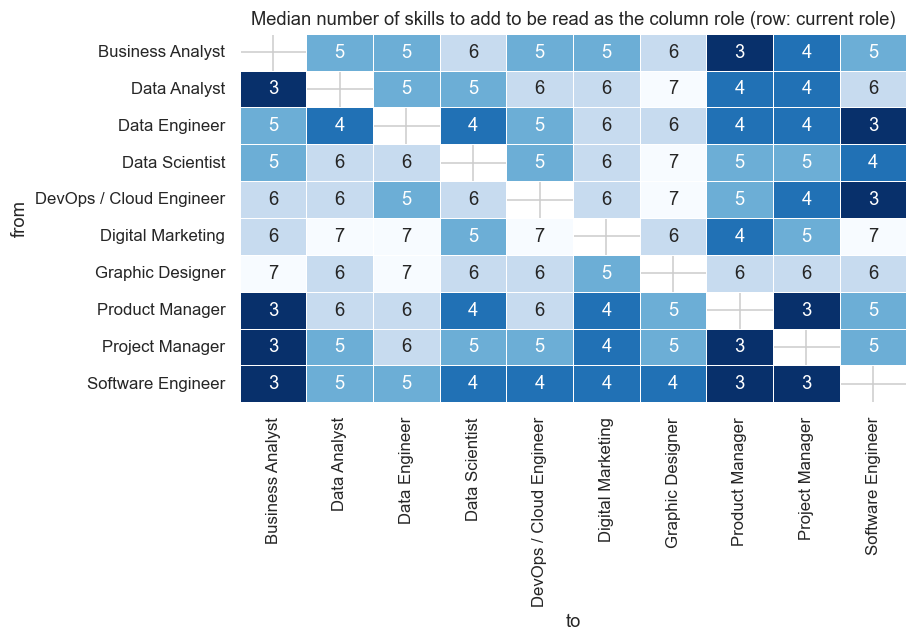

,from,to,flip_5,median_added,naive_flip_5,naive_median_added
44,DevOps / Cloud Engineer,Software Engineer,0.82,3.0,0.23,5.0
81,Software Engineer,Business Analyst,0.72,3.0,0.48,4.0
79,Project Manager,Product Manager,0.86,3.0,0.72,3.0
72,Project Manager,Business Analyst,0.80,3.0,0.60,5.0
70,Product Manager,Project Manager,0.89,3.0,0.78,4.0
63,Product Manager,Business Analyst,0.92,3.0,0.58,5.0


,from,to,flip_5,flip_10,median_added
41,DevOps / Cloud Engineer,Graphic Designer,0.16,0.65,7.0
56,Graphic Designer,Data Engineer,0.18,0.55,7.0
49,Digital Marketing,DevOps / Cloud Engineer,0.19,0.50,7.0
62,Graphic Designer,Software Engineer,0.19,0.53,6.0
47,Digital Marketing,Data Engineer,0.21,0.56,7.0
37,DevOps / Cloud Engineer,Data Analyst,0.22,0.65,6.0


In [60]:
SW_W, SW_B = sw_lr.coef_, sw_lr.intercept_
def sw_scores(x): return SW_W @ x + SW_B
ROLE_NOUNS = {"engineer", "engineers", "analyst", "scientist", "manager", "designer", "developer", "sde"}
role_name_skill = np.array([any(w in ROLE_NOUNS for w in re.findall(r"[a-z]+", s_)) for s_ in sw_skills])
MIN_SHARE = 0.10
share_role = np.array([sw_X[yc == k].mean(0) for k in range(len(CLASSES))])           # share of postings of each role that ask for each skill
def feasible(target): return (share_role[target] >= MIN_SHARE) & ~role_name_skill
def sw_recourse(x, target, max_add=10):
    x = x.copy(); added = []
    for _ in range(max_add):
        z = sw_scores(x)
        if int(np.argmax(z)) == target: break
        z2 = z.copy(); z2[target] = -np.inf; rival = int(np.argmax(z2))
        gain = SW_W[target] - SW_W[rival]; gain[x > 0] = -np.inf; gain[~feasible(target)] = -np.inf
        i = int(np.argmax(gain))
        if gain[i] <= 0: break
        x[i] = 1; added.append(i)
    return added, bool(np.argmax(sw_scores(x)) == target)
def sw_naive(x, target, cur, max_add=10):
    x = x.copy(); added = []
    order = [i_ for i_ in np.argsort(-(share_role[target] - share_role[cur])) if feasible(target)[i_]]
    for i in order:
        if len(added) >= max_add or int(np.argmax(sw_scores(x))) == target: break
        if x[i] == 0: x[i] = 1; added.append(int(i))
    return added, bool(np.argmax(sw_scores(x)) == target)
pairs_rows, first_picks = [], {}
te_pred = sw_pred
for a in range(len(CLASSES)):
    idx = te_c[(yc[te_c] == a) & (te_pred == a)]                                       # postings of role a that the classifier also reads as role a
    for t in range(len(CLASSES)):
        if t == a: continue
        g_n, n_n, picks = [], [], Counter()
        for i in idx:
            ad, ok = sw_recourse(sw_X[i], t); g_n.append(len(ad) if ok else np.nan)
            nv, ok2 = sw_naive(sw_X[i], t, a); n_n.append(len(nv) if ok2 else np.nan)
            for s_ in ad[:5]: picks[s_] += 1
        g_n, n_n = np.array(g_n, float), np.array(n_n, float)
        pairs_rows.append({"from": CLASSES[a], "to": CLASSES[t], "postings": int(len(idx)), "flip_10": float(np.mean(~np.isnan(g_n))), "flip_5": float(np.mean(g_n <= 5)),
                           "median_added": float(np.nanmedian(g_n)) if (~np.isnan(g_n)).any() else None,
                           "naive_flip_10": float(np.mean(~np.isnan(n_n))), "naive_flip_5": float(np.mean(n_n <= 5)), "naive_median_added": float(np.nanmedian(n_n)) if (~np.isnan(n_n)).any() else None})
        first_picks[(a, t)] = [(sw_skills[s_], c_ / max(len(idx), 1)) for s_, c_ in picks.most_common(8)]
sw_pairs = pd.DataFrame(pairs_rows)
tot = sw_pairs["postings"].sum()
sw_overall = {k: float(np.average(sw_pairs[k].fillna(0), weights=sw_pairs["postings"])) for k in ("flip_5", "flip_10", "naive_flip_5", "naive_flip_10")}
sw_overall["median_added"] = float(sw_pairs["median_added"].median()); sw_overall["naive_median_added"] = float(sw_pairs["naive_median_added"].median())
print(f"Across all {len(sw_pairs)} role moves ({tot:,} posting-moves): flipped within 5 skills {sw_overall['flip_5']:.1%}, within 10 {sw_overall['flip_10']:.1%}; median skills added {sw_overall['median_added']:.0f}")
print(f"Naive baseline (add the target's most common missing skills): within 5 {sw_overall['naive_flip_5']:.1%}, within 10 {sw_overall['naive_flip_10']:.1%}; median {sw_overall['naive_median_added']:.0f}")
M_med = sw_pairs.pivot(index="from", columns="to", values="median_added").reindex(index=CLASSES, columns=CLASSES)
plt.figure(figsize=(8.5, 6)); sns.heatmap(M_med, annot=True, fmt=".0f", cmap="Blues_r", cbar=False, linewidths=.5); plt.title("Median number of skills to add to be read as the column role (row: current role)"); plt.tight_layout(); plt.show()
display(sw_pairs.sort_values("median_added").head(6)[["from", "to", "flip_5", "median_added", "naive_flip_5", "naive_median_added"]].round(2))
display(sw_pairs.sort_values("flip_5").head(6)[["from", "to", "flip_5", "flip_10", "median_added"]].round(2))

**Finding.** Skills alone are enough to read a role: a classifier on 200 skills places 90.3% of the 2,064 test postings in the right role (macro-F1 0.888), as many as reading the whole description (about 90%) and more than the employer's tags alone (83.7%). The search is limited to skills a target role really asks for: at least 10% of its postings, and not role names such as `data engineer`. Without that limit it reaches the target faster (64.7% within five added skills) but by picking rare, heavily weighted skills, for example `google analytics` on the way to Data Engineer, which 1% of Data Engineer postings ask for; those flips are not advice anyone could use. With the limit, across all 90 role moves, a posting reaches the target role within 5 added skills in 48.1% of cases and within 10 in 84.3%, with a median of 5 skills, against 29.2% and 61.7% (median 6) for the baseline that adds the target role's most common missing skills from the same list. Neighbouring roles are about three skills apart: Product Manager to Business Analyst (92% within five), Product Manager to Project Manager (89%), Project Manager to Product Manager (86%) and DevOps / Cloud to Software Engineer (82%). Data Analyst to Data Engineer takes a median of five (53% within five, 90% within ten), with suggestions such as big data, PySpark, CI/CD and ETL. Distant roles take six or seven and about half or fewer flip within ten (Digital Marketing to DevOps / Cloud: 50%). A flip means the classifier reads the posting as the target role. It says nothing about whether a person would be hired, and the pay associations beside each skill are the market-wide figures from section 7, most of them not clear.

In [61]:
# the browser demo: classifier weights, shares of each role asking for each skill, pay associations, the check above
sw_prem = {r.skill: {"pct": float((np.exp(r.dml_beta) - 1) * 100), "clear": bool(r.dml_fdr_sig or r.ols_fdr_sig), "n": int(r.n_postings)} for r in prem.itertuples()} if "prem" in globals() else {}
top_pairs = {f"{CLASSES[a]}|{CLASSES[t]}": [{"skill": s_, "pick": float(c_), "share_to": float(share_role[t][sw_skills.index(s_)]), "share_from": float(share_role[a][sw_skills.index(s_)])} for s_, c_ in v] for (a, t), v in first_picks.items()}
switch = {
    "classes": CLASSES, "skills": sw_skills, "coef": [[round(float(x_), 3) for x_ in row_] for row_ in SW_W], "intercept": [round(float(x_), 4) for x_ in SW_B],
    "share": [[round(float(x_), 4) for x_ in row_] for row_ in share_role], "role_name": [bool(b_) for b_ in role_name_skill], "min_share": MIN_SHARE, "premium": sw_prem, "metrics": sw_metrics, "overall": sw_overall,
    "pairs": json.loads(sw_pairs.to_json(orient="records", double_precision=4)), "top": top_pairs, "n_role": {CLASSES[k]: int((yc == k).sum()) for k in range(len(CLASSES))},
}
print("switch payload ready:", len(json.dumps(switch)) // 1000, "KB")

switch payload ready: 145 KB


# 10. Skill Bundles and Text-only Salary

Two further analyses that use only the text.

**Skill bundles.** Skills that appear together far more often than chance form a network (an edge links two skills when their lift is above 1.5 and they co-occur in at least 30 postings). Community detection (Louvain, edge weight = log lift) groups the network into **bundles**: sets of skills that employers tend to ask for together. A posting's score on a bundle is the share of that bundle's skills it asks for.

**How much of pay can the words alone tell?** Four interpretable text features are built from the description only: the bundle scores, the 8 topic shares, the similarity of the text to each role's typical wording, and a **text-derived seniority index**, a single number per posting that predicts the experience asked for from the words alone (ridge regression on TF-IDF, out-of-fold by company; the salary is never used). They are compared with the 50 SVD dimensions of the same text, with and without experience and role as controls. Scores are company-grouped cross-validated R².

200 skills and 4439 edges; 6 bundles of size [41, 31, 41, 36, 23, 28]
   digital marketing, analytics, seo, google analytics, social media, marketing, social media marketing, research, sem, google adwords
   automation, cloud, aws, architecture, devops, azure, deployment, operations, docker, kubernetes
   python, sql, ai, data analysis, machine learning, analytical, computer science, data science, data quality, data analytics
   agile, project management, communication skills, business analysis, compliance, product management, scrum, business analyst, jira, business requirements
   photoshop, illustrator, graphic designing, graphics, adobe creative suite, corel draw, design, video editing, banners, graphic designer
   javascript, html, java, programming, software development, apis, software engineer, css, application development, debugging


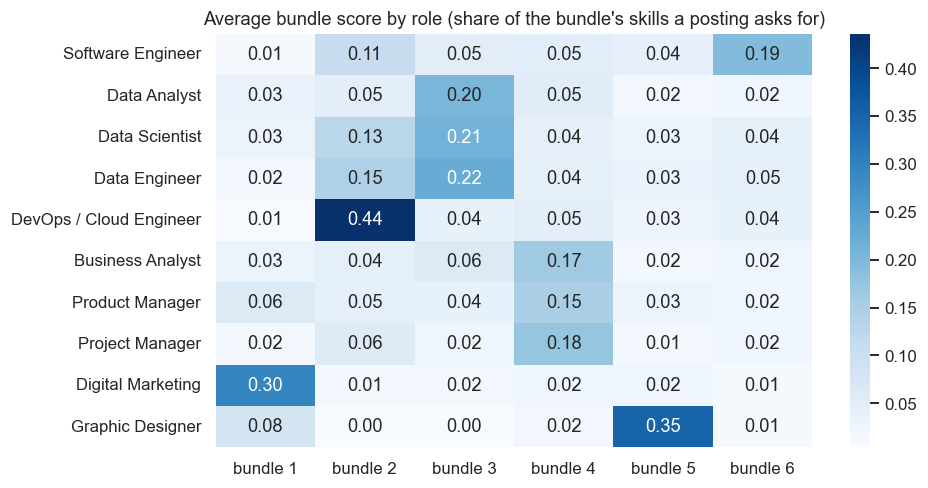

In [62]:
import networkx as nx
A_ = U.values.astype(float); n_ = len(A_); pr_ = A_.mean(0); co_ = A_.T @ A_
Gx = nx.Graph()
for i in range(len(VOCAB)):
    for j in range(i + 1, len(VOCAB)):
        if co_[i, j] >= 30:
            lift = co_[i, j] / (n_ * pr_[i] * pr_[j])
            if lift > 1.5: Gx.add_edge(i, j, weight=float(np.log(lift)), lift=float(lift), together=int(co_[i, j]))
comms = sorted([sorted(c_) for c_ in nx.community.louvain_communities(Gx, weight="weight", seed=SEED) if len(c_) >= 4], key=lambda c_: -sum(pr_[i] for i in c_))
BUNDLES = [[VOCAB[i] for i in c_] for c_ in comms]
print(f"{Gx.number_of_nodes()} skills and {Gx.number_of_edges()} edges; {len(BUNDLES)} bundles of size {[len(b) for b in BUNDLES]}")
for b in BUNDLES: print("  ", ", ".join(b[:10]))
Bscore = np.column_stack([A_[:, c_].mean(1) for c_ in comms])
role_in_bundle = pd.DataFrame(Bscore, columns=[f"bundle {k + 1}" for k in range(len(comms))]).groupby(corp["role"].values).mean().loc[CORE_ROLES]
plt.figure(figsize=(9, 4.6)); sns.heatmap(role_in_bundle, annot=True, fmt=".2f", cmap="Blues"); plt.title("Average bundle score by role (share of the bundle's skills a posting asks for)"); plt.tight_layout(); plt.show()


### Reading the bundles
- **Six bundles** come out of 200 skills and 4,439 links: marketing (digital marketing, SEO, Google Analytics, social media), cloud and DevOps (automation, cloud, AWS, Azure, Docker, Kubernetes), data (Python, SQL, machine learning, data analysis), delivery and business analysis (agile, project management, scrum, business analysis, Jira), design (Photoshop, Illustrator, CorelDRAW, video editing) and software development (JavaScript, HTML, Java, APIs, CSS).
- **Roles show up without being named.** Each role scores highest on one bundle: DevOps / Cloud on the cloud bundle (0.44 of its skills asked on average), Graphic Designer on design (0.35), Digital Marketing on marketing (0.30), Software Engineer on software development (0.19). Business Analyst, Product Manager and Project Manager all lead on delivery and business analysis (0.15 to 0.18). **Data Analyst, Data Scientist and Data Engineer all share the data bundle** (0.20 to 0.22), which is also why these three roles are the hardest to tell apart in section 9.


In [63]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold as GKF

Xn_ = normalize(Xtf)
cent = normalize(np.vstack([np.asarray(Xn_[(corp["role"] == r).values].mean(0)).ravel() for r in CORE_ROLES]))
ROLE_SIM = np.asarray(Xn_ @ cent.T)
sen = np.zeros(len(corp))
for a_, b_ in GKF(5).split(Xtf, corp["exp_mid"].values, groups=corp["company_key"].values):
    sen[b_] = Ridge(alpha=3.0).fit(Xtf[a_], corp["exp_mid"].values[a_]).predict(Xtf[b_])
sen_r2 = r2_score(corp["exp_mid"], sen)
print(f"Experience predicted from the description alone (out-of-fold by company): R2 {sen_r2:.3f}")
allpay = np.arange(len(y))
CT2 = CTRL.loc[:, [c_ for c_ in CTRL.columns if c_.startswith(("exp_", "role_"))]].values
fe = lambda M_: M_[P]
TXT = {
  "50 SVD dimensions of the text": fe(Z),
  "bundle scores (6)": fe(Bscore),
  "topic shares (8)": fe(THETA[K_TOPIC]),
  "similarity to each role's wording (10)": fe(ROLE_SIM),
  "text-derived seniority index (1)": fe(sen[:, None]),
  "all four interpretable features (25)": np.hstack([fe(Bscore), fe(THETA[K_TOPIC]), fe(ROLE_SIM), fe(sen[:, None])]),
}
rows = []
for name, Xt_ in TXT.items():
    r_ = {"features": name, "columns": Xt_.shape[1]}
    for l in ("Ridge", "XGBoost"):
        r_[f"text only, {l}"] = cv_r2(Xt_, LEARNERS[l], idx=allpay)[0]
        r_[f"+ experience and role, {l}"] = cv_r2(np.hstack([CT2, Xt_]), LEARNERS[l], idx=allpay)[0]
    rows.append(r_)
base_ = {"features": "experience and role only", "columns": CT2.shape[1]}
for l in ("Ridge", "XGBoost"): base_[f"+ experience and role, {l}"] = cv_r2(CT2, LEARNERS[l], idx=allpay)[0]
TEXT_ONLY = pd.DataFrame([base_] + rows).set_index("features")
TEXT_ONLY.style.format("{:.3f}", na_rep="-", subset=[c_ for c_ in TEXT_ONLY.columns if c_ != "columns"])

Experience predicted from the description alone (out-of-fold by company): R2 0.430


,columns,"+ experience and role, Ridge","+ experience and role, XGBoost","text only, Ridge","text only, XGBoost"
features,,,,,
experience and role only,13,0.635,0.652,-,-
50 SVD dimensions of the text,50,0.685,0.688,0.521,0.525
bundle scores (6),6,0.641,0.644,0.283,0.316
topic shares (8),8,0.646,0.650,0.366,0.360
similarity to each role's wording (10),10,0.664,0.677,0.450,0.442
text-derived seniority index (1),1,0.652,0.660,0.394,0.409
all four interpretable features (25),25,0.675,0.681,0.537,0.500



### Reading the text-only results
- **The words alone carry about half of the variation in pay.** With no experience, role or city given, the four interpretable features (bundle scores, topic shares, similarity to each role's wording, the seniority index) reach R² 0.537 with Ridge and 0.500 with XGBoost, against 0.521 and 0.525 for the 50 SVD dimensions. In a linear model 25 readable columns do as well as 50 opaque ones; in XGBoost they are a little behind.
- **One number carries a lot.** The text-derived seniority index, which predicts the years of experience asked for from the description alone (out-of-fold R² 0.430), reaches 0.394 (Ridge) and 0.409 (XGBoost) as the only input.
- **Once experience and role are known, the gain from the text is small.** On top of experience and role (R² 0.635 and 0.652), the SVD adds +0.050 and +0.036, the four interpretable features +0.040 and +0.029, role similarity +0.029 and +0.025, the seniority index +0.017 and +0.008. Topic shares and bundle scores alone add little (between −0.008 and +0.011).
- The seniority index is learned from the experience field, so it is weakly supervised; the salary is never used.


# 11. Export for the dashboard

The tables in this notebook are written to `frontend/src/data/` as JSON so that the web dashboard shows exactly these numbers.

In [64]:
OUT = ROOT / "frontend" / "src" / "data"; OUT.mkdir(parents=True, exist_ok=True)
def recs(obj, index_name="name"):
    if isinstance(obj, dict): obj = pd.DataFrame(obj).T
    obj = obj.copy(); obj.index = obj.index.map(lambda v: v if isinstance(v, (str, int, float)) else str(v))
    obj.index.name = index_name
    return json.loads(obj.reset_index().to_json(orient="records", double_precision=5))
def long(df_, row="row", col="col", val="value"):
    s_ = df_.copy(); s_.index.name = row; s_.columns.name = col
    return json.loads(s_.stack().rename(val).reset_index().to_json(orient="records", double_precision=5))

Lc = corp["text"].str.len()
lh, le = np.histogram(Lc.clip(upper=6000), bins=30, range=(0, 6000))
mine_ = {"tags_any": float(T.any(axis=1).mean()), "text_any": float(M.any(axis=1).mean()), "either_any": float(U.any(axis=1).mean()),
         "mean_tags": float(T.sum(axis=1).mean()), "mean_text": float(M.sum(axis=1).mean()), "mean_either": float(U.sum(axis=1).mean())}
tagged_ = int(Tm.values.sum())
trunc_ = {"tagged": tagged_, "in_text": float((Tm.values & Mfull.values).sum() / tagged_), "in_first500": float((Tm.values & M5.values).sum() / tagged_),
          "mentions_first500": float(M5.values.sum() / len(sample)), "mentions_full": float(Mfull.values.sum() / len(sample))}
placebo_ = {"fp_mean": float(np.mean(fp)), "fp_p95": float(np.percentile(fp, 95)), "fdr_mean": float(np.mean(nsig)), "fdr_max": int(max(nsig)),
            "real_flagged": float((prem["ols_p"] < .05).mean()), "real_fdr": int(prem["ols_fdr_sig"].sum())}
agree_ = {"spearman": json.loads(prem[["ols_beta", "ridge_beta", "dml_beta"]].corr(method="spearman").round(3).to_json()), "same_sign": float(same_sign.mean())}
ctrl_ = {"matrix": recs(cab.loc[pick], "skill"), "median_share_left": float(shrink.median()), "n_above": int(len(shrink))}
conf_ = [{"count": int(c_), "true": a_, "pred": b_} for c_, a_, b_ in pairs]
cm_full = confusion_matrix(yc[te_c], pf, normalize="true"); cm_mask = confusion_matrix(yc[te_c], pm, normalize="true")
text = {
    "funnel": [{"label": "Scraped postings", "n": int(len(df))}, {"label": "Matched to one of the 10 roles", "n": int(n0)}, {"label": "With a real description", "n": int(n1)},
               {"label": "Distinct descriptions (the corpus)", "n": int(len(corp))}, {"label": "State a salary", "n": int(n_stated)}, {"label": "Salary set after screens", "n": int(len(pay))}],
    "roles": recs(pd.concat([corp["role"].value_counts().rename("corpus"), pay["role"].value_counts().rename("pay_set")], axis=1).loc[CORE_ROLES], "role"),
    "length_hist": {"edges": [float(v) for v in le], "counts": [int(v) for v in lh], "share_over_500": float((Lc > 500).mean()), "median": int(Lc.median())},
    "tags_top": [{"tag": t_, "n": int(c_)} for t_, c_ in tag_counts.most_common(20)], "tag_role_share": long(share.loc[:, CORE_ROLES], "tag", "role", "pct"),
    "mining": mine_, "trunc": trunc_, "tag_recall": recs(rec, "skill"), "pairs": recs(PAIRS.set_index(["skill_a"]), "skill_a"), "terms": TERMS,
    "topic_k": recs(tk, "K"), "topics": recs(tw, "topic"), "topic_role": long(tr, "role", "topic", "share"), "k_topic": int(K_TOPIC),
    "clusters": long(ct, "cluster", "role", "share"), "cluster_nmi": float(nmi(role_codes, km.labels_)),
    "exp_grid": [{"set": s_, "learner": l_, "r2": float(mean.loc[s_, l_]), "sd": float(sd.loc[s_, l_])} for s_ in mean.index for l_ in mean.columns],
    "abl_source": recs(ABL_SOURCE, "source"), "abl_vocab": recs(ABL_VOCAB, "vocabulary"), "abl_topics": recs(ABL_TOPICS.reset_index().assign(model=lambda d: d["model"] + " " + d["K"].astype(str)).set_index("model")[["Ridge", "XGBoost"]], "model"),
    "abl_trunc": recs(ABL_TRUNC, "variant"),
    "ratio_mean": long(PAY_RATIO["mean"], "learner_split", "set", "r2") if False else [{"learner": a_, "split": b_, "set": c_, "r2": float(PAY_RATIO["mean"].loc[(a_, b_), c_]), "sd": float(PAY_RATIO["sd"].loc[(a_, b_), c_])} for (a_, b_) in PAY_RATIO["mean"].index for c_ in PAY_RATIO["mean"].columns],
    "ratio_gain": [{"learner": a_, "split": b_, "set": c_, "gain": float(PAY_RATIO["gain"].loc[(a_, b_), c_])} for (a_, b_) in PAY_RATIO["gain"].index for c_ in PAY_RATIO["gain"].columns],
    "premiums": recs(prem.set_index("skill"), "skill"), "agree": agree_, "placebo": placebo_, "stability": [{"split": k_, **{f"{a_}_{b_}": float(st.loc[k_, (a_, b_)]) for a_, b_ in st.columns}} for k_ in st.index],
    "controls": ctrl_, "topic_prem": recs(tp.set_index("topic"), "topic"), "eval": recs(ev.reset_index().assign(name=lambda d: d["feature set"] + " | " + d["learner"]).set_index("name")[["R2_test", "MAE_INR"]], "name"),
    "holdout_prem": recs(cmp_, "skill") if "cmp_" in globals() else [], "selected": list(map(str, sel_names)),
}
role_skills = {}
for r_ in CORE_ROLES:
    m_ = (corp["role"] == r_).values
    tag_s, ask_s = T[m_].mean() * 100, U[m_].mean() * 100
    role_skills[r_] = [{"skill": s_, "ask_pct": round(float(ask_s[s_]), 1), "tag_pct": round(float(tag_s[s_]), 1)} for s_ in tag_s.sort_values(ascending=False).head(15).index]
text["role_skills"] = role_skills
json.dump(text, open(OUT / "textmining.json", "w"), ensure_ascii=False)
json.dump(disclosure, open(OUT / "disclosure.json", "w"), ensure_ascii=False)
json.dump(switch, open(OUT / "switch.json", "w"), ensure_ascii=False)
roles = {
    "classes": CLASSES, "n_train": int(len(tr_c)), "n_test": int(len(te_c)), "class_share": recs((RC["role"].value_counts(normalize=True) * 100).rename("pct").to_frame(), "role"),
    "models": recs(rcdf, "model"), "repr": recs(rr, "variant"), "grid": long(g, "length", "masking", "macro_f1"), "features": recs(ft, "input"), "weights": recs(cw, "setting") if False else [{"model": k_[0], "weights": k_[1], **v_} for k_, v_ in cw.items()],
    "ratio": [{"input": a_, "split": b_, "mean": float(tbl.loc[(a_, b_), "mean"]), "sd": float(tbl.loc[(a_, b_), "std"])} for (a_, b_) in tbl.index],
    "final": recs(summ, "model"), "per_role": recs(per, "role"), "confusion_full": cm_full.round(4).tolist(), "confusion_masked": cm_mask.round(4).tolist(),
    "words": {k_: {"full": v_[0], "masked": v_[1]} for k_, v_ in RC_WORDS.items()}, "confusions": conf_, "own_title_share": float(own),
}
json.dump(roles, open(OUT / "roles.json", "w"), ensure_ascii=False)
node_ids = sorted(Gx.nodes, key=lambda i: -pr_[i])[:90]; sub = Gx.subgraph(node_ids)
pos = nx.spring_layout(sub, weight="weight", seed=SEED, k=0.9, iterations=200)
bundle_of = {i: k for k, c_ in enumerate(comms) for i in c_}
network = {
    "bundles": [{"id": k, "skills": b_, "size": len(b_)} for k, b_ in enumerate(BUNDLES)],
    "nodes": [{"skill": VOCAB[i], "bundle": int(bundle_of.get(i, -1)), "demand_pct": float(100 * pr_[i]), "x": float(pos[i][0]), "y": float(pos[i][1])} for i in sub.nodes],
    "edges": [{"a": VOCAB[i], "b": VOCAB[j], "lift": float(d_["lift"]), "together": d_["together"]} for i, j, d_ in sub.edges(data=True) if d_["lift"] >= 2.5],
    "role_in_bundle": long(role_in_bundle, "role", "bundle", "score"),
    "text_only": recs(TEXT_ONLY.reset_index().set_index("features"), "features"), "seniority_r2": float(sen_r2),
}
json.dump(network, open(OUT / "network.json", "w"), ensure_ascii=False)
print("Wrote", sorted(p.name for p in OUT.glob("*.json")))

Wrote ['calculator.json', 'dataset.json', 'demo.json', 'disclosure.json', 'gap.json', 'network.json', 'roles.json', 'salary.json', 'switch.json', 'textmining.json', 'trends.json']



# 12. Business Interpretation

**Role fit**
1. **A description identifies its role with macro-F1 about 0.88** on companies the model never saw (accuracy 0.90), against 0.03 for guessing. A simple linear model on TF-IDF is enough; more complex models do not improve it.
2. **It reads the job, not the job title.** Removing every role-naming word, or each posting's own title words, changes the score by only 0.01 to 0.03, and a model trained without the title words scores the same on the test companies.
3. **Analyst roles are the hard cases.** Business Analyst and Data Analyst (F1 about 0.80) are confused with each other and with project, product and data engineering roles, because they describe overlapping work. Marketing and design roles are almost perfectly recognised.
4. **The old 500-character limit would have cost accuracy here:** macro-F1 falls from 0.889 to 0.839 with the first 500 characters and from 0.862 to 0.754 when the role-naming words are removed as well.
5. **Skill tags and text complement each other** (0.906 together against 0.889 for text and 0.801 for tags).

**Skill bundles and the words alone**
5a. **Skills travel in six bundles**, found without being told about roles: marketing, cloud and DevOps, data, delivery and business analysis, design, and software development. Each role has one dominant bundle (DevOps / Cloud 0.44, Graphic Designer 0.35, Digital Marketing 0.30) except the three data roles, which share the data bundle.
5b. **The words alone carry about half of the variation in pay** (R² 0.52 to 0.54 with no experience, role or city given). Four interpretable features, built from the text only, match the 50-dimension SVD in a linear model (0.537 against 0.521). A single text-derived seniority index, which predicts years of experience from the description (R² 0.43), reaches 0.39 to 0.41 on its own.

**Skills, topics and pay**
6. **Named skills explain little pay beyond the basics.** Once experience, role, seniority, city, work mode and industry are known, listing skills or adding topics raises prediction accuracy by at most about 0.01 R² on unseen companies. What helps more is the overall wording of the description (+0.03 R² in cross-validation). This agrees with the salary model, where the description text was the second most important input after experience.
7. **A handful of skills go with higher or lower pay at the same experience and role.** After controls, `bash`, `PMP`, `performance marketing` and `analytical skills` go with about 18% to 26% higher pay; `off-page optimization`, `graphic designer`, `corel draw` and `video editing` go with about 16% to 19% lower pay. About one skill in five is distinguishable from zero, intervals are wide (about ±0.15 log points), and the ranking of the rest is unstable (rank correlation about 0.3 across company splits).
8. **Most of a raw skill premium is seniority.** Controlling for experience and role removes about 88% of the median raw gap.
9. **Topics.** Postings in a product and analytics register pay about 8% more per standard deviation of that language, and heavy marketing language goes with about 19% lower pay within a role.
10. **The 500-character limit** would have kept only about a third of the skill mentions (4.5 against 12.5 per posting). It made no measurable difference to predicting pay, but it would have lowered role fit (point 4).

**How reliable is it**
11. Three different estimators rank skills alike (rank correlation 0.77 to 0.94); a placebo test shows the procedure flags about 6% of skills when nothing is there, against 19% on the real data. The role-fit model's result is the same at 80/20, 70/30 and 60/40 splits.
12. Everything about pay is **association, not cause**: a skill may stand in for a better employer or a harder job.

**Limits**
13. Only about 13% of the postings in this corpus state a salary, and the pay results describe those postings. The sample is about 1,350 salaried postings from about 1,000 companies, one snapshot.
14. Skill matching in free text is keyword-based; some entries are ordinary words, and short tokens had to be taken from the employer tags only. The text models (vocabulary, topics, SVD, clusters) were fitted on all text without salary or role, so test-company text took part in fitting them.
15. Role comes from the title, which makes some "errors" label noise and caps the achievable accuracy below 100%. Salaries are ranges that employers choose to publish.

**Next steps:** collect more salaried postings (especially Software Engineer and Data Scientist), estimate premiums within each role, and add posting dates to see whether premiums move over time.
